In [ ]:
# --- data paths (see README: data layout) ---
import os
from pathlib import Path

# Root of the data store. Override with the DATA_ROOT environment variable.
DATA_ROOT = os.environ.get(
    "DATA_ROOT",
    "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/AI-IFS-attributioncomparison/pnw2021",
)
# Root of this git repository (found by walking up from the working directory).
REPO = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts").is_dir()))


In [1]:
from pathlib import Path
import xarray as xr
import numpy as np
import tempfile
import subprocess
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.spatial import cKDTree
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
import ipywidgets as widgets
from IPython.display import display, clear_output
import re


import cartopy.crs as ccrs
import cartopy.feature as cfeature



In [2]:
ds = xr.open_dataset((DATA_ROOT + "/IC_Deltas/incr-co2-sstdelta-remap.grib"), engine="cfgrib")

print(ds)
print(ds.data_vars)

Ignoring index file '/home/a/andriychenko/Projects/graphcast/incr-co2-sstdelta-remap.grib.5b7b6.idx' incompatible with GRIB file


<xarray.Dataset> Size: 33MB
Dimensions:    (values: 1661440)
Coordinates:
    latitude   (values) float64 13MB ...
    longitude  (values) float64 13MB ...
    step       timedelta64[ns] 8B ...
    surface    float64 8B ...
Dimensions without coordinates: values
Data variables:
    unknown    (values) float32 7MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             0
    GRIB_centreDescription:  Absent
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             Absent
    history:                 2026-09-24T13:54 GRIB to CDM+CF via cfgrib-0.9.1...
Data variables:
    unknown  (values) float32 7MB ...


First few cells are for checking if the remapping I am doing is correct

In [3]:
def remap_grib_and_apply_to_sst(
    grib_path,
    init_nc_path,
    out_nc_path,
    target_var="sea_surface_temperature",
    cdo_bin="cdo",
):
    """
    Regularise a reduced-Gaussian GRIB with CDO, remap it to the target
    NetCDF lon/lat grid, verify the remap worked, and apply the delta to SST.

    Parameters
    ----------
    grib_path : str or Path
        Input GRIB file (e.g. pi-co2-sstdelta-remap.grib)
    init_nc_path : str or Path
        Target initialisation NetCDF (e.g. init_2021-06-25T12_10d.nc)
    out_nc_path : str or Path
        Output NetCDF to write
    target_var : str
        Variable in the NetCDF to add the delta to
    cdo_bin : str
        CDO executable name/path

    Returns
    -------
    out_ds : xarray.Dataset
        Dataset after delta application
    remap_ds : xarray.Dataset
        The remapped delta dataset opened from CDO output
    """
    grib_path = Path(grib_path)
    init_nc_path = Path(init_nc_path)
    out_nc_path = Path(out_nc_path)

    # Load target dataset
    init_ds = xr.open_dataset(init_nc_path)
    if target_var not in init_ds:
        raise KeyError(f"{target_var!r} not found in {init_nc_path}")

    if "lat" not in init_ds.coords or "lon" not in init_ds.coords:
        raise ValueError("Target NetCDF must have 'lat' and 'lon' coordinates")

    lat = init_ds["lat"].values
    lon = init_ds["lon"].values

    # Build a CDO grid description file for the target grid
    with tempfile.TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)
        gridfile = tmpdir / "target_grid.txt"
        regular_grib = tmpdir / "regularised.grib"
        remap_nc = tmpdir / "remapped.nc"

        with gridfile.open("w") as f:
            f.write("gridtype = lonlat\n")
            f.write(f"xsize    = {len(lon)}\n")
            f.write(f"ysize    = {len(lat)}\n")
            f.write(f"xfirst   = {float(lon[0])}\n")
            f.write(f"xinc     = {float(lon[1] - lon[0])}\n")
            f.write(f"yfirst   = {float(lat[0])}\n")
            f.write(f"yinc     = {float(lat[1] - lat[0])}\n")

        # 1) Regularise reduced Gaussian grid
        cmd1 = [cdo_bin, "setgridtype,regular", str(grib_path), str(regular_grib)]
        subprocess.run(cmd1, check=True)

        # 2) Remap onto target lon/lat grid
        cmd2 = [cdo_bin, "-f", "nc", f"remapbil,{gridfile}", str(regular_grib), str(remap_nc)]
        subprocess.run(cmd2, check=True)

        # Re-open remapped output
        remap_ds = xr.open_dataset(remap_nc, use_cftime=True)

        if len(remap_ds.data_vars) == 0:
            raise RuntimeError("Remapped file contains no data variables")

        delta_name = list(remap_ds.data_vars)[0]
        delta = remap_ds[delta_name]

        # CDO often leaves a dummy time axis of length 1
        if "time" in delta.dims and delta.sizes["time"] == 1:
            delta = delta.isel(time=0)

        # Make sure the result is a 2D lat/lon field
        if set(delta.dims) != {"lat", "lon"}:
            raise RuntimeError(
                f"Remapped field has unexpected dims {delta.dims}; expected ('lat', 'lon')"
            )

        # Verify grid match
        if delta.shape != (len(lat), len(lon)):
            raise RuntimeError(
                f"Remapped shape {delta.shape} does not match target grid {(len(lat), len(lon))}"
            )

        if not np.allclose(delta["lat"].values, lat):
            raise RuntimeError("Latitude coordinates do not match the target grid")

        if not np.allclose(delta["lon"].values, lon):
            raise RuntimeError("Longitude coordinates do not match the target grid")

        # Apply delta to the target variable. xarray will broadcast lat/lon
        # across batch/time automatically.
        delta_da = xr.DataArray(
            delta.values,
            coords={"lat": init_ds["lat"], "lon": init_ds["lon"]},
            dims=("lat", "lon"),
            name=f"{target_var}_delta",
        )

        out_ds = init_ds.copy()
        out_ds[target_var] = init_ds[target_var] + delta_da

        out_ds.to_netcdf(out_nc_path)

    return out_ds, remap_ds

In [4]:
def test_remap_grib_and_apply_to_sst(
    grib_path,
    init_nc_path,
    target_var="sea_surface_temperature",
    cdo_bin="cdo",
):
    """
    Dry-run test:
    - writes to a temporary output file
    - verifies remap grid
    - verifies SST changed
    - prints a small summary
    """
    grib_path = Path(grib_path)
    init_nc_path = Path(init_nc_path)

    with tempfile.TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)
        test_out = tmpdir / "test_output.nc"

        out_ds, remap_ds = remap_grib_and_apply_to_sst(
            grib_path=grib_path,
            init_nc_path=init_nc_path,
            out_nc_path=test_out,
            target_var=target_var,
            cdo_bin=cdo_bin,
        )

        init_ds = xr.open_dataset(init_nc_path, use_cftime=True)

        delta_name = list(remap_ds.data_vars)[0]
        delta = remap_ds[delta_name]
        if "time" in delta.dims and delta.sizes["time"] == 1:
            delta = delta.isel(time=0)

        assert delta.dims == ("lat", "lon"), f"Unexpected delta dims: {delta.dims}"
        assert delta.shape == (init_ds.sizes["lat"], init_ds.sizes["lon"]), "Grid shape mismatch"
        assert np.allclose(delta["lat"].values, init_ds["lat"].values), "Latitude mismatch"
        assert np.allclose(delta["lon"].values, init_ds["lon"].values), "Longitude mismatch"

        before = init_ds[target_var].values
        after = out_ds[target_var].values
        diff = after - before

        assert np.nanmax(np.abs(diff)) > 0, "No change applied to target variable"
        assert test_out.exists(), "Temporary output file was not written"

        print("Test passed.")
        print("Remapped variable:", delta_name)
        print("Delta min/max:", float(np.nanmin(delta.values)), float(np.nanmax(delta.values)))
        print("Applied diff min/max:", float(np.nanmin(diff)), float(np.nanmax(diff)))

In [5]:


test_remap_grib_and_apply_to_sst(
    grib_path=(DATA_ROOT + "/IC_Deltas/pi-co2-sstdelta-remap.grib"),
    init_nc_path=(DATA_ROOT + "/gencast/init/current/ic_1deg_current_init-2021-06-26T00_10d.nc"),
    target_var="sea_surface_temperature",
)

cdo    remapbil: Bilinear weights from gaussian (2576x1280) to lonlat (360x181) grid


/tmp/user/28413/ipykernel_3526080/3350190960.py:72: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  remap_ds = xr.open_dataset(remap_nc, use_cftime=True)


Test passed.
Remapped variable: code1
Delta min/max: -5.449851989746094 1.3921808004379272
Applied diff min/max: -5.449859619140625 1.392181396484375


/tmp/user/28413/ipykernel_3526080/2055833970.py:29: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  init_ds = xr.open_dataset(init_nc_path, use_cftime=True)


In [6]:
#run only if you want to output the file!
#out_ds, remap_ds = remap_grib_and_apply_to_sst(
#    grib_path="/home/a/andriychenko/Projects/graphcast/incr-co2-sstdelta-remap.grib",
#    init_nc_path="/home/a/andriychenko/Projects/graphcast/init_files/init_2021-06-25T12_10d.nc",
#    out_nc_path="/home/a/andriychenko/Projects/graphcast/incr_co2_withsstdelta_init_2021-06-25T12_10d.nc",
#    target_var="sea_surface_temperature",
#)

In [7]:
grib_path = (DATA_ROOT + "/IC_Deltas/pi-co2-sstdelta-remap.grib")
init_nc_path = (DATA_ROOT + "/gencast/init/current/ic_1deg_current_init-2021-06-26T00_10d.nc")
out_nc_path = (DATA_ROOT + "/gencast/init/pi/ic_1deg_pi_init-2021-06-26T00_10d.nc")


Residual check:
  max abs residual = 5.462141e-01
  mean residual    = 1.951427e-04


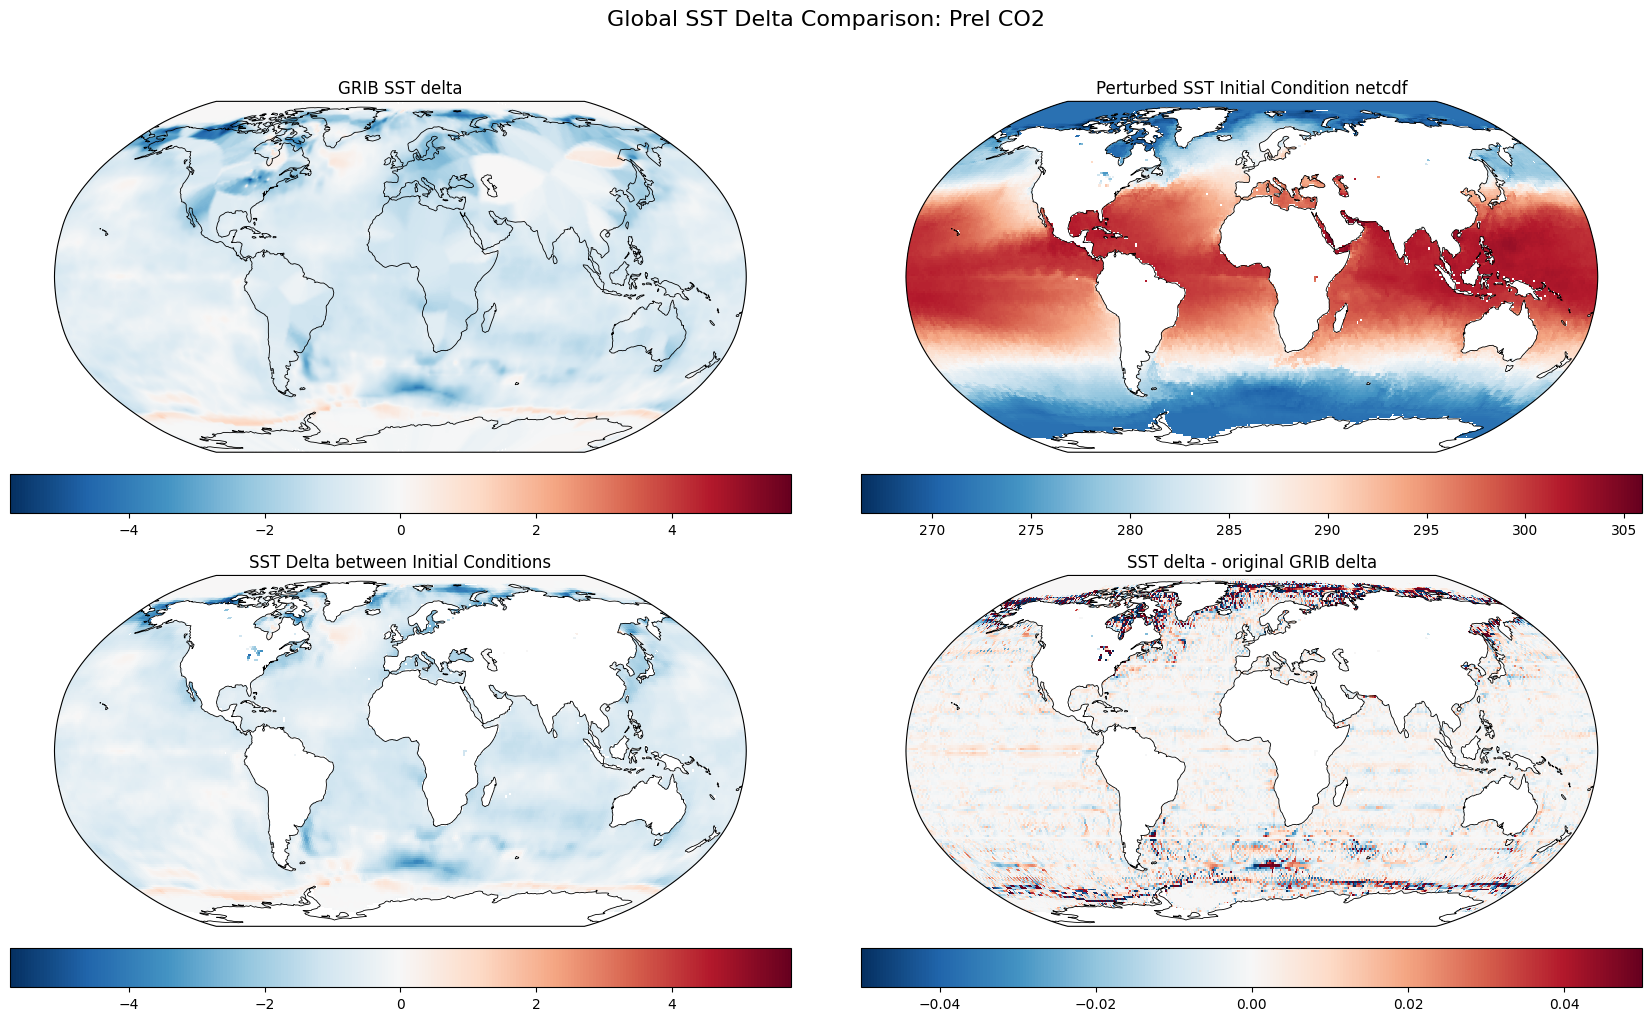

In [8]:
def canonicalize_1d_latlon(da):
    lat_name = next((n for n in ["latitude", "lat", "LATITUDE", "nav_lat"] if n in da.coords), None)
    lon_name = next((n for n in ["longitude", "lon", "LONGITUDE", "nav_lon"] if n in da.coords), None)

    if lat_name is None or lon_name is None:
        raise ValueError(f"Could not find lat/lon coords. dims={da.dims}, coords={list(da.coords)}")

    if lat_name not in da.dims and da[lat_name].ndim == 1:
        da = da.swap_dims({da[lat_name].dims[0]: lat_name})
    if lon_name not in da.dims and da[lon_name].ndim == 1:
        da = da.swap_dims({da[lon_name].dims[0]: lon_name})

    rename_map = {}
    if lat_name != "latitude":
        rename_map[lat_name] = "latitude"
    if lon_name != "longitude":
        rename_map[lon_name] = "longitude"
    if rename_map:
        da = da.rename(rename_map)

    lon = da["longitude"].values
    if np.nanmax(lon) > 180:
        da = da.assign_coords(longitude=((da["longitude"] + 180) % 360) - 180)

    return da.sortby("latitude").sortby("longitude").squeeze(drop=True)


def open_nc_sst(path):
    ds = xr.open_dataset(path)
    da = ds["sea_surface_temperature"].squeeze(drop=True)

    while da.ndim > 2:
        da = da.isel({da.dims[0]: 0}).squeeze(drop=True)

    return canonicalize_1d_latlon(da)


def open_grib_points(path):
    ds = xr.open_dataset(path, engine="cfgrib", backend_kwargs={"indexpath": ""})
    da = ds["unknown"].squeeze(drop=True)

    if "values" not in da.dims:
        da = canonicalize_1d_latlon(da)
        return da

    lat = np.asarray(da["latitude"].values)
    lon = np.asarray(da["longitude"].values)
    vals = np.asarray(da.values)

    mask = np.isfinite(lat) & np.isfinite(lon) & np.isfinite(vals)
    lat = lat[mask]
    lon = lon[mask]
    vals = vals[mask]

    if np.nanmax(lon) > 180:
        lon = ((lon + 180) % 360) - 180

    return lat, lon, vals


def sample_points_to_grid(lat_pts, lon_pts, vals_pts, lat_grid, lon_grid):
    """
    Nearest-neighbour sample from scattered GRIB points onto a regular grid.
    This avoids xarray interp() on a point cloud.
    """
    tree = cKDTree(np.column_stack([lon_pts, lat_pts]))
    query_lon, query_lat = np.meshgrid(lon_grid, lat_grid)
    query_points = np.column_stack([query_lon.ravel(), query_lat.ravel()])
    _, idx = tree.query(query_points, k=1)
    sampled = vals_pts[idx].reshape(query_lat.shape)

    return xr.DataArray(
        sampled,
        coords={"latitude": lat_grid, "longitude": lon_grid},
        dims=("latitude", "longitude"),
        name="grib_sampled",
    )


def plot_grid(ax, da, title, cmap="RdBu_r", vmin=None, vmax=None):
    da = da.squeeze(drop=True).transpose("latitude", "longitude")
    lat = da["latitude"].values
    lon = da["longitude"].values
    data = da.values

    data_cyc, lon_cyc = add_cyclic_point(data, coord=lon)

    mesh = ax.pcolormesh(
        lon_cyc,
        lat,
        data_cyc,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(title)
    ax.coastlines(linewidth=0.6)
    ax.set_global()
    plt.colorbar(mesh, ax=ax, orientation="horizontal", pad=0.05, shrink=0.85)
    return mesh


def plot_grib_points(ax, lat_pts, lon_pts, vals_pts, title, cmap="RdBu_r", vmin=None, vmax=None):
    sc = ax.scatter(
        lon_pts,
        lat_pts,
        c=vals_pts,
        s=1,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        transform=ccrs.PlateCarree(),
        linewidths=0,
        rasterized=True,
    )
    ax.set_title(title)
    ax.coastlines(linewidth=0.6)
    ax.set_global()
    plt.colorbar(sc, ax=ax, orientation="horizontal", pad=0.05, shrink=0.85)
    return sc


# Load NetCDF fields
init_da = open_nc_sst(init_nc_path)
out_da = open_nc_sst(out_nc_path)

# Load GRIB as raw scattered points
grib_lat, grib_lon, grib_vals = open_grib_points(grib_path)

# Make sure init/out are on the same grid
init_da, out_da = xr.align(init_da, out_da, join="inner")
delta_nc = out_da - init_da

# Sample GRIB points onto the NetCDF grid for comparison
grib_on_grid = sample_points_to_grid(
    grib_lat,
    grib_lon,
    grib_vals,
    init_da["latitude"].values,
    init_da["longitude"].values,
)

# Residual check
residual = delta_nc - grib_on_grid

print("Residual check:")
print(f"  max abs residual = {float(np.nanmax(np.abs(residual.values))):.6e}")
print(f"  mean residual    = {float(np.nanmean(residual.values)):.6e}")

# Shared scale for delta-style panels
delta_max = float(np.nanmax(np.abs(np.concatenate([
    grib_vals.ravel(),
    delta_nc.values.ravel(),
    residual.values.ravel(),
]))))

# Plot
fig = plt.figure(figsize=(18, 10))

ax1 = plt.subplot(2, 2, 1, projection=ccrs.Robinson())
plot_grib_points(ax1, grib_lat, grib_lon, grib_vals, "GRIB SST delta", cmap="RdBu_r", vmin=-delta_max, vmax=delta_max)

ax2 = plt.subplot(2, 2, 2, projection=ccrs.Robinson())
plot_grid(ax2, out_da, "Perturbed SST Initial Condition netcdf", cmap="RdBu_r")

ax3 = plt.subplot(2, 2, 3, projection=ccrs.Robinson())
plot_grid(ax3, delta_nc, "SST Delta between Initial Conditions", cmap="RdBu_r", vmin=-delta_max, vmax=delta_max)

ax4 = plt.subplot(2, 2, 4, projection=ccrs.Robinson())
plot_grid(ax4, residual, "SST delta - original GRIB delta", cmap="RdBu_r", vmin=-0.05, vmax=0.05)

fig.suptitle("Global SST Delta Comparison: PreI CO2", fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

In [9]:
perturbed_zarr_path = (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_seed0_26ens.zarr")   # folder or zarr store
unperturbed_zarr_path = (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed0_26ens.zarr")   # folder or zarr storevar_name = "sea_surface_temperature"             # change if needed
var = "sea_surface_temperature"

In [10]:
perturbed_zarr_path = (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_seed0_26ens.zarr")   # folder or zarr store
unperturbed_zarr_path = (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed0_26ens.zarr")   # folder or zarr storevar_name = "sea_surface_temperature"             # change if needed
var = "sea_surface_temperature"

unperturbed = xr.open_zarr(unperturbed_zarr_path)[var]
perturbed   = xr.open_zarr(perturbed_zarr_path)[var]

# ---------------------------------------------------------
# 2. Standardize coordinate names
# ---------------------------------------------------------
def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

unperturbed = standardize(unperturbed)
perturbed   = standardize(perturbed)

init_time = np.datetime64("2021-06-18T00:00:00")
unperturbed = unperturbed.assign_coords(time=init_time + unperturbed.time)
perturbed   = perturbed.assign_coords(time=init_time + perturbed.time)

def collapse_extra_dims(da):
    for dim in ["batch", "number", "sample", "member", "ensemble"]:
        if dim in da.dims:
            da = da.mean(dim)
    return da

unperturbed = collapse_extra_dims(unperturbed)
perturbed   = collapse_extra_dims(perturbed)

unperturbed, perturbed = xr.align(unperturbed, perturbed, join="inner")

# ---------------------------------------------------------
# 4. Convert to Celsius and compute difference
# ---------------------------------------------------------
unperturbed = unperturbed - 273.15
perturbed   = perturbed - 273.15
diff        = perturbed - unperturbed

# ---------------------------------------------------------
# 5. Tidy dims
# ---------------------------------------------------------
def tidy(da):
    base = [d for d in ["time", "lat", "lon"] if d in da.dims]
    rest = [d for d in da.dims if d not in base]
    return da.transpose(*base, *rest) if base else da

unperturbed = tidy(unperturbed)
perturbed   = tidy(perturbed)
diff        = tidy(diff)

times = unperturbed.time.values
time_labels = [
    np.datetime_as_string(t, unit="h") if np.issubdtype(times.dtype, np.datetime64) else str(t)
    for t in times
]
slider_options = [(label, i) for i, label in enumerate(time_labels)]

# ---------------------------------------------------------
# 6. Plot helpers
# ---------------------------------------------------------
extent = [
    float(min(unperturbed.lon.min(), perturbed.lon.min())),
    float(max(unperturbed.lon.max(), perturbed.lon.max())),
    float(min(unperturbed.lat.min(), perturbed.lat.min())),
    float(max(unperturbed.lat.max(), perturbed.lat.max())),
]

sst_vals = np.concatenate([unperturbed.values.ravel(), perturbed.values.ravel()])
sst_vmin = np.nanpercentile(sst_vals, 2)
sst_vmax = np.nanpercentile(sst_vals, 98)

diff_abs = np.nanpercentile(np.abs(diff.values), 98)
diff_vmin = -diff_abs
diff_vmax = diff_abs

def draw_panel(ax, da2d, title, cmap, vmin, vmax, cbar_label):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.coastlines(resolution="10m", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.25)

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 9}
    gl.ylabel_style = {"size": 9}

    im = ax.pcolormesh(
        da2d.lon,
        da2d.lat,
        da2d,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(title)
    cbar = ax.figure.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.set_label(cbar_label)

slider = widgets.SelectionSlider(
    options=slider_options,
    value=0,
    description="Time",
    continuous_update=False,
    layout={"width": "800px"},
)

out = widgets.Output()

def show_frame(frame, pert):
    with out:
        clear_output(wait=True)

        # Force the selected timestep to load now, so the callback does not stall
        #unp_t = unperturbed.isel(time=frame).load()
        p_t = perturbed.isel(time=frame).load()
        dif_t = diff.isel(time=frame).load()

        fig, axes = plt.subplots(
            1, 2,
            figsize=(14, 6),
            subplot_kw={"projection": ccrs.PlateCarree()},
            constrained_layout=True
        )

        draw_panel(
            axes[0],
            p_t,
            "Perturbed SST",
            cmap="RdBu_r",
            vmin=sst_vmin,
            vmax=sst_vmax,
            cbar_label="SST (°C)"
        )

        draw_panel(
            axes[1],
            dif_t,
            "Perturbed - Unperturbed SST",
            cmap="RdBu_r",
            vmin=diff_vmin,
            vmax=diff_vmax,
            cbar_label="Difference (°C)"
        )

        fig.suptitle(f"{var} {pert} comparison — {time_labels[frame]}", fontsize=13)
        plt.show()
        plt.close(fig)

slider.observe(lambda change: show_frame(change["new"], "Incr CO2") if change["name"] == "value" else None, names="value")

display(widgets.VBox([slider, out]))
show_frame(0, "Incr CO2")

In [11]:
perturbed_zarr_path = (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-22T00_18d/pred_1deg_pi_init-2021-06-22T00_18d_seed0_26ens.zarr")   # folder or zarr store
unperturbed_zarr_path = (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed0_26ens.zarr")   # folder or zarr storevar_name = "sea_surface_temperature"             # change if needed
var = "sea_surface_temperature"

unperturbed = xr.open_zarr(unperturbed_zarr_path)[var]
perturbed   = xr.open_zarr(perturbed_zarr_path)[var]

# ---------------------------------------------------------
# 2. Standardize coordinate names
# ---------------------------------------------------------
def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

unperturbed = standardize(unperturbed)
perturbed   = standardize(perturbed)

init_time = np.datetime64("2021-06-18T00:00:00")
unperturbed = unperturbed.assign_coords(time=init_time + unperturbed.time)
perturbed   = perturbed.assign_coords(time=init_time + perturbed.time)

unperturbed = collapse_extra_dims(unperturbed)
perturbed   = collapse_extra_dims(perturbed)

unperturbed, perturbed = xr.align(unperturbed, perturbed, join="inner")

# ---------------------------------------------------------
# 4. Convert to Celsius and compute difference
# ---------------------------------------------------------
unperturbed = unperturbed - 273.15
perturbed   = perturbed - 273.15
diff        = perturbed - unperturbed


unperturbed = tidy(unperturbed)
perturbed   = tidy(perturbed)
diff        = tidy(diff)

times = unperturbed.time.values
time_labels = [
    np.datetime_as_string(t, unit="h") if np.issubdtype(times.dtype, np.datetime64) else str(t)
    for t in times
]
slider_options = [(label, i) for i, label in enumerate(time_labels)]

# ---------------------------------------------------------
# 6. Plot helpers
# ---------------------------------------------------------
extent = [
    float(min(unperturbed.lon.min(), perturbed.lon.min())),
    float(max(unperturbed.lon.max(), perturbed.lon.max())),
    float(min(unperturbed.lat.min(), perturbed.lat.min())),
    float(max(unperturbed.lat.max(), perturbed.lat.max())),
]

sst_vals = np.concatenate([unperturbed.values.ravel(), perturbed.values.ravel()])
sst_vmin = np.nanpercentile(sst_vals, 2)
sst_vmax = np.nanpercentile(sst_vals, 98)

diff_abs = np.nanpercentile(np.abs(diff.values), 98)
diff_vmin = -diff_abs
diff_vmax = diff_abs


slider = widgets.SelectionSlider(
    options=slider_options,
    value=0,
    description="Time",
    continuous_update=False,
    layout={"width": "800px"},
)

out = widgets.Output()

slider.observe(lambda change: show_frame(change["new"], "Pre Ind CO2") if change["name"] == "value" else None, names="value")

display(widgets.VBox([slider, out]))
show_frame(0, "Pre Ind CO2")

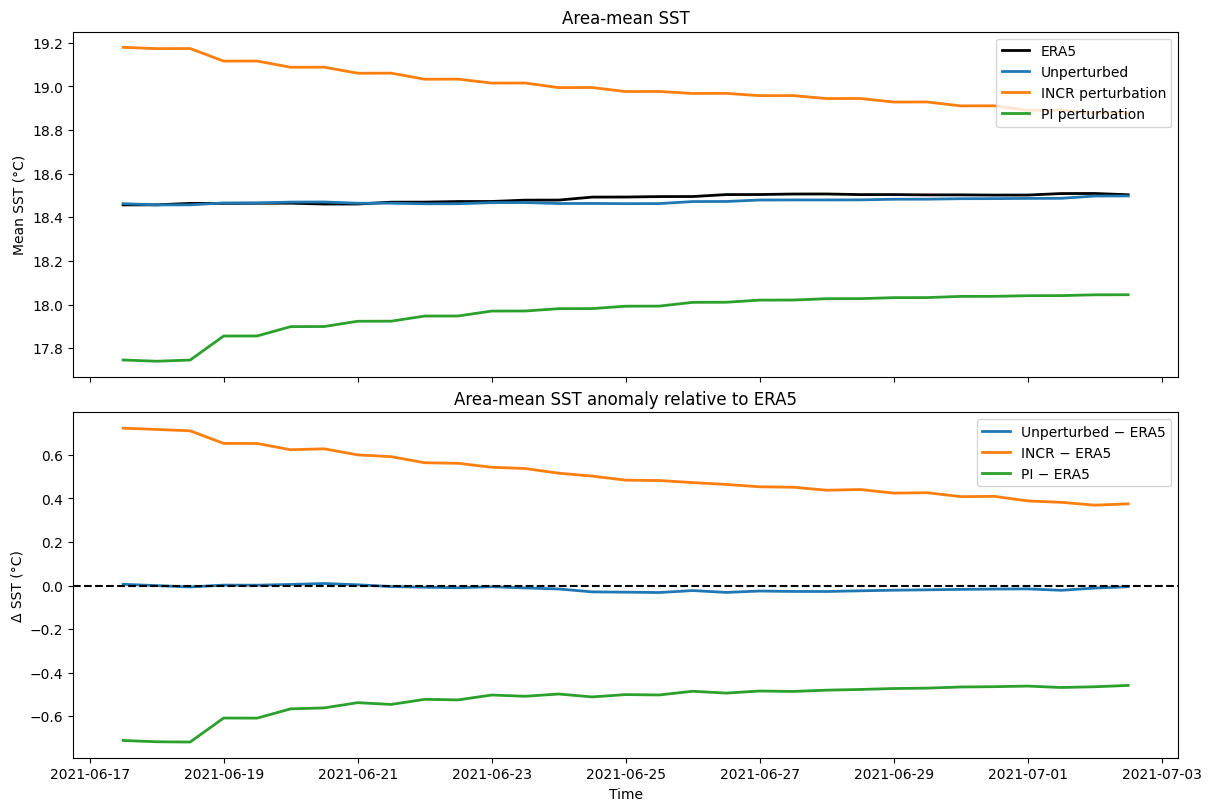

In [12]:
unperturbed_paths = [
    (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_stitched_50ens.zarr")
]
era5_path = (DATA_ROOT + "/gencast/init/tests/init_2021-06-17T12_30d.nc")
var = "sea_surface_temperature"

scenario_paths = {
    "incr": [
        (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_stitched_50ens.zarr"),
    ],
    "pi": [
        (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_stitched_50ens.zarr"),
    ],
}

# -------------------------------------------------------------------
# Helpers
# -------------------------------------------------------------------
def open_any(path):
    if path.endswith(".zarr"):
        return xr.open_zarr(path)
    return xr.open_dataset(path)

def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

def extract_date_from_path(path):
    m = re.search(r"(20\d{2}-\d{2}-\d{2})", path)
    return np.datetime64(m.group(1) + "T00:00:00") if m else None

def squeeze_series(da):
    return da.squeeze(drop=True)

def to_valid_time(da, init_time):
    if "time" not in da.coords or init_time is None:
        return da

    t = da["time"]

    if np.issubdtype(t.dtype, np.datetime64):
        return da

    if np.issubdtype(t.dtype, np.timedelta64):
        return da.assign_coords(time=init_time + t)

    if np.issubdtype(t.dtype, np.number):
        return da.assign_coords(time=init_time + t * np.timedelta64(1, "h"))

    return da

def collapse_extra_dims(da):
    for dim in ["batch", "number", "sample", "member", "ensemble"]:
        if dim in da.dims:
            da = da.mean(dim)
    return da

def load_many(paths, var):
    das = []
    for p in paths:
        ds = open_any(p)
        da = ds[var]
        da = standardize(da)
        da = to_valid_time(da, extract_date_from_path(p))
        da = collapse_extra_dims(da)
        das.append(da)

    if len(das) == 1:
        return das[0]

    return xr.concat(das, dim="time").sortby("time")

def area_weighted_mean(da):
    if "lat" not in da.dims or "lon" not in da.dims:
        return da.mean()

    weights = np.cos(np.deg2rad(da["lat"]))
    return da.weighted(weights).mean(dim=("lat", "lon"), skipna=True)

# -------------------------------------------------------------------
# Load data
# -------------------------------------------------------------------
unperturbed = load_many(unperturbed_paths, var)

era5_ds = open_any(era5_path)
era5 = standardize(era5_ds[var])
era5 = to_valid_time(era5, extract_date_from_path(era5_path))

# Convert K -> C
unperturbed = unperturbed - 273.15
era5 = era5 - 273.15

# Align unperturbed with ERA5
unperturbed, era5 = xr.align(unperturbed, era5, join="inner")

# Area-mean time series
unpert_mean = squeeze_series(area_weighted_mean(unperturbed))
era5_mean = squeeze_series(area_weighted_mean(era5))

# Keep only the common time axis for plotting
unpert_mean, era5_mean = xr.align(unpert_mean, era5_mean, join="inner")
unpert_delta = squeeze_series(unpert_mean - era5_mean)

# -------------------------------------------------------------------
# Load perturbed scenarios
# -------------------------------------------------------------------
scenario_means = {}
scenario_deltas = {}

for name, paths in scenario_paths.items():
    da = load_many(paths, var)
    da = da - 273.15  # K -> C

    da, era5_aligned = xr.align(da, era5, join="inner")

    mean = squeeze_series(area_weighted_mean(da))
    era5_mean_aligned = squeeze_series(area_weighted_mean(era5_aligned))

    mean, era5_mean_aligned = xr.align(mean, era5_mean_aligned, join="inner")

    scenario_means[name] = mean
    scenario_deltas[name] = squeeze_series(mean - era5_mean_aligned)

# -------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

# Top panel: mean SST
axes[0].plot(
    era5_mean.time,
    era5_mean,
    label="ERA5",
    linewidth=2,
    color="black",
)

axes[0].plot(
    unpert_mean.time,
    unpert_mean,
    label="Unperturbed",
    linewidth=2,
)

for name, series in scenario_means.items():
    axes[0].plot(
        series.time,
        series,
        linewidth=2,
        label=f"{name.upper()} perturbation",
    )

axes[0].set_ylabel("Mean SST (°C)")
axes[0].set_title("Area-mean SST")
axes[0].legend()

# Bottom panel: delta vs ERA5
axes[1].plot(
    unpert_delta.time,
    unpert_delta,
    linewidth=2,
    label="Unperturbed − ERA5",
)

for name, delta in scenario_deltas.items():
    axes[1].plot(
        delta.time,
        delta,
        linewidth=2,
        label=f"{name.upper()} − ERA5",
    )

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Δ SST (°C)")
axes[1].set_title("Area-mean SST anomaly relative to ERA5")
axes[1].legend()

plt.xlabel("Time")
plt.show()

In [13]:
pi_col_orig = "#0e42a3"
incr_col_orig = "#c90c0c"
oper_col_orig = "#595959"
pi_col_gencast = "#93b5f5"
incr_col_gencast = "#f56f6f"
oper_col_gencast = "#a0a0a0"

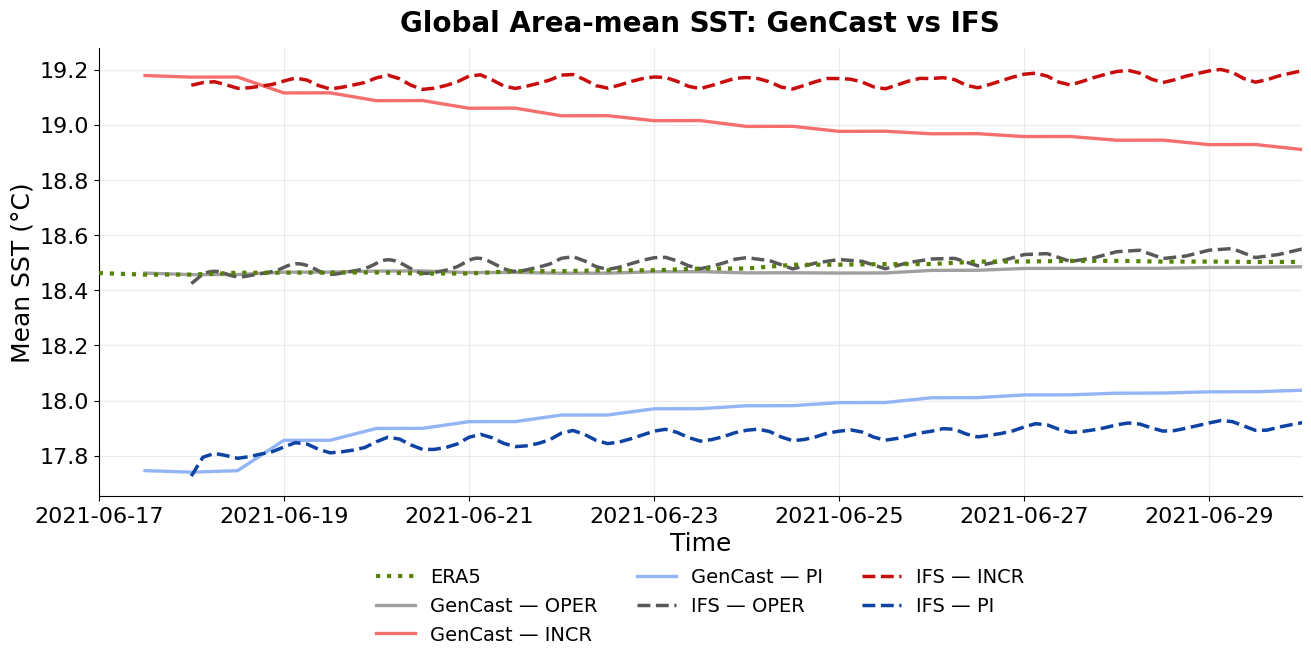

In [19]:
# ================================================================
# Paths
# ================================================================
BASE = DATA_ROOT + "/"

Gencast_unperturbed = [
    BASE + "gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_stitched_50ens.zarr"
]

Gencast_scenarios = {
    "incr": [
        BASE
        + "gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_stitched_50ens.zarr"
    ],
    "pi": [
        BASE
        + "gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_stitched_50ens.zarr"
    ],
}

IFS_unperturbed = [
    BASE + "ifs/sfc/oper_cf_2021-06-18_allarea_sst_and_seaice.nc"
]

IFS_scenarios = {
    "incr": [BASE + "ifs/sfc/incr_cf_2021-06-18_allarea_sst_and_seaice.nc"],
    "pi": [BASE + "ifs/sfc/pi_cf_2021-06-18_allarea_sst_and_seaice.nc"],
}

ERA5 = DATA_ROOT + "/gencast/init/tests/init_2021-06-17T12_30d.nc"

VAR_GENCAST = "sea_surface_temperature"
VAR_IFS = "sst"


# ================================================================
# Plot colours
# ================================================================
pi_col_orig = "#0e42a3"
incr_col_orig = "#c90c0c"
oper_col_orig = "#595959"

pi_col_gencast = "#93b5f5"
incr_col_gencast = "#f56f6f"
oper_col_gencast = "#a0a0a0"

era5_col = "#568203"


# ================================================================
# Helpers
# ================================================================
def open_var(path, var):
    """Open one variable from Zarr or NetCDF and standardise coordinates."""
    ds = (
        xr.open_zarr(path)
        if path.endswith(".zarr")
        else xr.open_dataset(path)
    )
    da = ds[var]

    rename = {}

    for old, new in (
        ("latitude", "lat"),
        ("longitude", "lon"),
    ):
        if old in da.coords or old in da.dims:
            rename[old] = new

    for old in ("sample", "member"):
        if old in da.dims:
            rename[old] = "number"

    if rename:
        da = da.rename(rename)

    # Convert forecast lead time to valid time when needed.
    if "time" in da.coords:
        match = re.search(r"(20\d{2}-\d{2}-\d{2})", path)

        if match:
            init = np.datetime64(match.group(1) + "T00:00:00")
            time = da.time

            if np.issubdtype(time.dtype, np.timedelta64):
                da = da.assign_coords(time=init + time)

            elif np.issubdtype(time.dtype, np.number):
                da = da.assign_coords(
                    time=init + time * np.timedelta64(1, "h")
                )

    # Collapse ensemble/member dimensions once, before the spatial mean.
    for dim in ("batch", "number", "sample", "member", "ensemble"):
        if dim in da.dims:
            da = da.mean(dim)

    return da.sortby("lat") if "lat" in da.dims else da


def load_mean(paths, var, mask=None):
    """Load data, convert K->C, optionally mask, and calculate area mean."""
    arrays = [open_var(path, var) - 273.15 for path in paths]

    if len(arrays) == 1:
        da = arrays[0]
    else:
        da = xr.concat(arrays, dim="time").sortby("time")

    if mask is not None:
        da = da.where(mask)

    if "lat" not in da.dims or "lon" not in da.dims:
        return da.squeeze(drop=True).mean()

    weights = np.cos(np.deg2rad(da.lat))

    return (
        da.weighted(weights)
        .mean(dim=("lat", "lon"), skipna=True)
        .squeeze(drop=True)
    )


# ================================================================
# ERA5
# ================================================================
era5_mean = load_mean([ERA5], VAR_GENCAST)


# ================================================================
# GenCast
# ================================================================
# Load unperturbed GenCast once; its NaNs define the ocean mask
# that is applied to IFS before the IFS area mean is calculated.
gencast_raw = open_var(
    Gencast_unperturbed[0],
    VAR_GENCAST,
) - 273.15

ocean_mask = (
    gencast_raw
    .isel(time=0)
    .notnull()
    .squeeze(drop=True)
)

gencast_unperturbed_mean = (
    gencast_raw
    .weighted(np.cos(np.deg2rad(gencast_raw.lat)))
    .mean(dim=("lat", "lon"), skipna=True)
    .squeeze(drop=True)
)

gencast_scenario_means = {
    name: load_mean(paths, VAR_GENCAST)
    for name, paths in Gencast_scenarios.items()
}


# ================================================================
# IFS
# Apply GenCast ocean mask BEFORE averaging
# ================================================================
ifs_unperturbed_mean = load_mean(
    IFS_unperturbed,
    VAR_IFS,
    mask=ocean_mask,
)

ifs_scenario_means = {
    name: load_mean(
        paths,
        VAR_IFS,
        mask=ocean_mask,
    )
    for name, paths in IFS_scenarios.items()
}


# ================================================================
# Final plot: mean SST only
# ================================================================
fig, ax = plt.subplots(
    figsize=(13, 6.5),
    constrained_layout=True,
)

# ------------------------------------------------
# ERA5
# ------------------------------------------------
ax.plot(
    era5_mean.time,
    era5_mean,
    label="ERA5",
    color=era5_col,
    linewidth=3,
    linestyle=":",
    zorder=5,
)


# ------------------------------------------------
# GenCast: solid lines
# ------------------------------------------------
ax.plot(
    gencast_unperturbed_mean.time,
    gencast_unperturbed_mean,
    label="GenCast — OPER",
    color=oper_col_gencast,
    linewidth=2.4,
)

gencast_colors = {
    "pi": pi_col_gencast,
    "incr": incr_col_gencast,
}

for name, series in gencast_scenario_means.items():
    ax.plot(
        series.time,
        series,
        label=f"GenCast — {name.upper()}",
        color=gencast_colors[name],
        linewidth=2.4,
    )


# ------------------------------------------------
# IFS: dashed lines
# ------------------------------------------------
ax.plot(
    ifs_unperturbed_mean.time,
    ifs_unperturbed_mean,
    label="IFS — OPER",
    color=oper_col_orig,
    linewidth=2.5,
    linestyle="--",
)

ifs_colors = {
    "pi": pi_col_orig,
    "incr": incr_col_orig,
}

for name, series in ifs_scenario_means.items():
    ax.plot(
        series.time,
        series,
        label=f"IFS — {name.upper()}",
        color=ifs_colors[name],
        linewidth=2.5,
        linestyle="--",
    )


# ================================================================
# Formatting
# ================================================================
ax.set_title(
    "Global Area-mean SST: GenCast vs IFS",
    fontsize=20,
    fontweight="bold",
    pad=12,
)

ax.set_xlabel("Time", fontsize=18)
ax.set_ylabel("Mean SST (°C)", fontsize=18)

ax.set_xlim(
    np.datetime64("2021-06-17"),
    np.datetime64("2021-06-30"),
)

ax.grid(
    alpha=0.25,
    linewidth=0.8,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", labelsize=16)

ax.legend(
    ncol=3,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    fontsize=14,
)

plt.show()


Arctic ocean area fraction = 3.47%

ARCTIC CONTRIBUTION TO SST RESPONSE

INCR
--------------------------------------------------------------------------------
GenCast
  Global ΔSST:       min= 0.3590, max= 0.7167 °C
  Arctic ΔSST:        min= 0.7977, max= 0.9356 °C
  Arctic contribution: min= 0.0277, max= 0.0325 °C
  Arctic % of global:   min= 4.53, max= 7.73 %

IFS
  Global ΔSST:       min= 0.6334, max= 0.7195 °C
  Arctic ΔSST:        min= 0.9216, max= 1.8565 °C
  Arctic contribution: min= 0.0320, max= 0.0645 °C
  Arctic % of global:   min= 4.45, max= 9.99 %

PI
--------------------------------------------------------------------------------
GenCast
  Global ΔSST:       min=-0.7167, max=-0.4461 °C
  Arctic ΔSST:        min=-1.5696, max=-0.9356 °C
  Arctic contribution: min=-0.0545, max=-0.0325 °C
  Arctic % of global:   min= 4.53, max= 11.95 %

IFS
  Global ΔSST:       min=-0.6985, max=-0.6192 °C
  Arctic ΔSST:        min=-0.8256, max=-0.5938 °C
  Arctic contribution: min=-0.0287, max

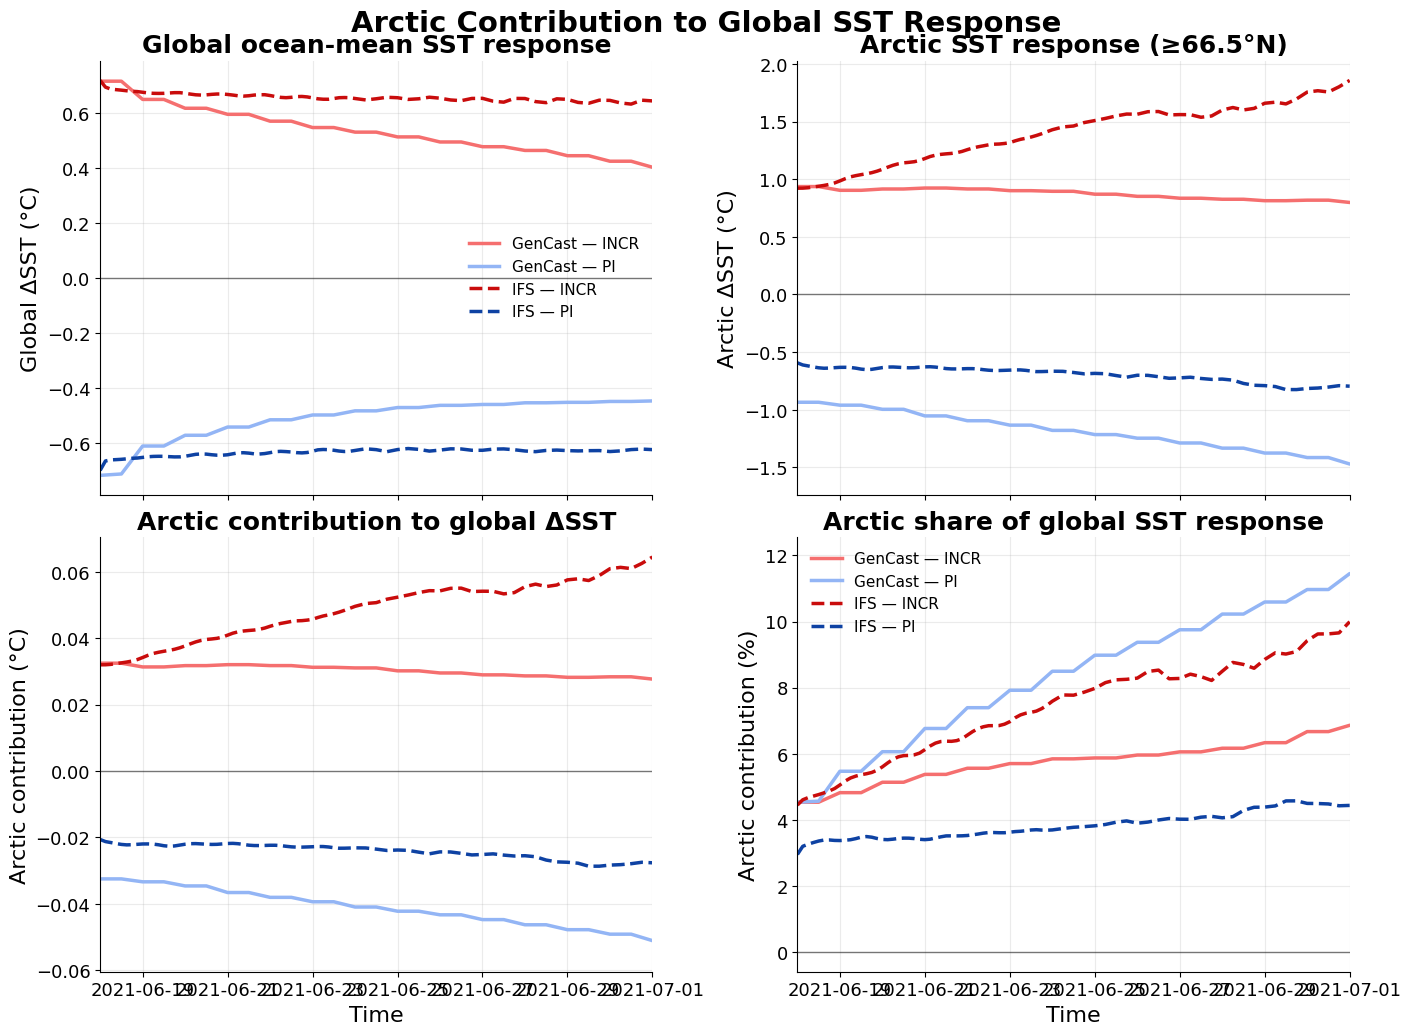

In [30]:
# ================================================================
# Arctic mask
# ================================================================

arctic_mask = gencast_oper.lat >= 66.5

arctic_ocean_mask = (
    ocean_mask
    & arctic_mask
)


# ================================================================
# Area weights
# ================================================================

weights = np.cos(
    np.deg2rad(gencast_oper.lat)
)


# ================================================================
# Helper:
# global and Arctic ocean-area means
# ================================================================

def global_and_arctic_mean(da):

    global_da = da.where(ocean_mask)
    arctic_da = da.where(arctic_ocean_mask)

    global_mean = (
        global_da
        .weighted(weights)
        .mean(
            dim=("lat", "lon"),
            skipna=True,
        )
        .squeeze(drop=True)
    )

    arctic_mean = (
        arctic_da
        .weighted(weights)
        .mean(
            dim=("lat", "lon"),
            skipna=True,
        )
        .squeeze(drop=True)
    )

    return global_mean, arctic_mean


# ================================================================
# Fraction of ocean area inside Arctic Circle
# ================================================================
global_area_weights = weights.broadcast_like(ocean_mask)
arctic_area_weights = weights.broadcast_like(arctic_ocean_mask)

global_ocean_area = (
    global_area_weights
    .where(ocean_mask)
    .sum(dim=("lat", "lon"))
)

arctic_ocean_area = (
    arctic_area_weights
    .where(arctic_ocean_mask)
    .sum(dim=("lat", "lon"))
)

# Dask -> NumPy scalar
arctic_area_fraction = (
    arctic_ocean_area / global_ocean_area
).compute().item()

print(
    f"Arctic ocean area fraction = "
    f"{100 * arctic_area_fraction:.2f}%"
)


# ================================================================
# Load all GenCast fields
# ================================================================

gencast_oper = (
    open_var(
        Gencast_unperturbed[0],
        VAR_GENCAST,
    )
    - 273.15
)

gencast_scenarios = {
    name: (
        open_var(
            paths[0],
            VAR_GENCAST,
        )
        - 273.15
    )
    for name, paths in Gencast_scenarios.items()
}


# ================================================================
# Load all IFS fields
# ================================================================

ifs_oper = (
    open_var(
        IFS_unperturbed[0],
        VAR_IFS,
    )
    - 273.15
)

ifs_scenarios = {
    name: (
        open_var(
            paths[0],
            VAR_IFS,
        )
        - 273.15
    )
    for name, paths in IFS_scenarios.items()
}


# ================================================================
# Calculate OPER means
# ================================================================

gencast_oper_global, gencast_oper_arctic = (
    global_and_arctic_mean(gencast_oper)
)

ifs_oper_global, ifs_oper_arctic = (
    global_and_arctic_mean(ifs_oper)
)


# ================================================================
# Calculate scenario means
# ================================================================

gencast_global = {}
gencast_arctic = {}

ifs_global = {}
ifs_arctic = {}

for name in ("incr", "pi"):

    gencast_global[name], gencast_arctic[name] = (
        global_and_arctic_mean(
            gencast_scenarios[name]
        )
    )

    ifs_global[name], ifs_arctic[name] = (
        global_and_arctic_mean(
            ifs_scenarios[name]
        )
    )


# ================================================================
# Calculate deltas
# ================================================================

gencast_global_delta = {}
gencast_arctic_delta = {}

ifs_global_delta = {}
ifs_arctic_delta = {}

for name in ("incr", "pi"):

    # Global SST delta
    gencast_global_delta[name] = (
        gencast_global[name]
        - gencast_oper_global
    )

    ifs_global_delta[name] = (
        ifs_global[name]
        - ifs_oper_global
    )

    # Arctic SST delta
    gencast_arctic_delta[name] = (
        gencast_arctic[name]
        - gencast_oper_arctic
    )

    ifs_arctic_delta[name] = (
        ifs_arctic[name]
        - ifs_oper_arctic
    )


# ================================================================
# Calculate Arctic contribution to GLOBAL delta
#
# contribution = area_fraction × Arctic SST delta
# ================================================================

gencast_arctic_contribution = {}
ifs_arctic_contribution = {}

for name in ("incr", "pi"):

    gencast_arctic_contribution[name] = (
        arctic_area_fraction
        * gencast_arctic_delta[name]
    )

    ifs_arctic_contribution[name] = (
        arctic_area_fraction
        * ifs_arctic_delta[name]
    )


# ================================================================
# Calculate percentage contribution
# ================================================================

gencast_arctic_percentage = {}
ifs_arctic_percentage = {}

for name in ("incr", "pi"):

    gencast_arctic_percentage[name] = (
        100
        * gencast_arctic_contribution[name]
        / gencast_global_delta[name]
    )

    ifs_arctic_percentage[name] = (
        100
        * ifs_arctic_contribution[name]
        / ifs_global_delta[name]
    )


# ================================================================
# Print diagnostics
# ================================================================

print("\n" + "=" * 80)
print("ARCTIC CONTRIBUTION TO SST RESPONSE")
print("=" * 80)

for name in ("incr", "pi"):

    print(f"\n{name.upper()}")
    print("-" * 80)

    # ------------------------------------------------------------
    # GenCast
    # ------------------------------------------------------------
    print("GenCast")

    print(
        "  Global ΔSST:"
        f"       min={float(gencast_global_delta[name].min().compute()): .4f},"
        f" max={float(gencast_global_delta[name].max().compute()): .4f} °C"
    )

    print(
        "  Arctic ΔSST:"
        f"        min={float(gencast_arctic_delta[name].min().compute()): .4f},"
        f" max={float(gencast_arctic_delta[name].max().compute()): .4f} °C"
    )

    print(
        "  Arctic contribution:"
        f" min={float(gencast_arctic_contribution[name].min().compute()): .4f},"
        f" max={float(gencast_arctic_contribution[name].max().compute()): .4f} °C"
    )

    print(
        "  Arctic % of global:"
        f"   min={float(gencast_arctic_percentage[name].min().compute()): .2f},"
        f" max={float(gencast_arctic_percentage[name].max().compute()): .2f} %"
    )

    # ------------------------------------------------------------
    # IFS
    # ------------------------------------------------------------
    print("\nIFS")

    print(
        "  Global ΔSST:"
        f"       min={float(ifs_global_delta[name].min().compute()): .4f},"
        f" max={float(ifs_global_delta[name].max().compute()): .4f} °C"
    )

    print(
        "  Arctic ΔSST:"
        f"        min={float(ifs_arctic_delta[name].min().compute()): .4f},"
        f" max={float(ifs_arctic_delta[name].max().compute()): .4f} °C"
    )

    print(
        "  Arctic contribution:"
        f" min={float(ifs_arctic_contribution[name].min().compute()): .4f},"
        f" max={float(ifs_arctic_contribution[name].max().compute()): .4f} °C"
    )

    print(
        "  Arctic % of global:"
        f"   min={float(ifs_arctic_percentage[name].min().compute()): .2f},"
        f" max={float(ifs_arctic_percentage[name].max().compute()): .2f} %"
    )


# ================================================================
# Plot
# ================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    sharex=True,
    constrained_layout=True,
)

# ================================================================
# PANEL 1
# Global SST delta
# ================================================================

ax = axes[0, 0]

ax.plot(
    gencast_global_delta["incr"].time,
    gencast_global_delta["incr"],
    color=incr_col_gencast,
    linewidth=2.5,
    label="GenCast — INCR",
)

ax.plot(
    gencast_global_delta["pi"].time,
    gencast_global_delta["pi"],
    color=pi_col_gencast,
    linewidth=2.5,
    label="GenCast — PI",
)

ax.plot(
    ifs_global_delta["incr"].time,
    ifs_global_delta["incr"],
    color=incr_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — INCR",
)

ax.plot(
    ifs_global_delta["pi"].time,
    ifs_global_delta["pi"],
    color=pi_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — PI",
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.set_title(
    "Global ocean-mean SST response",
    fontsize=18,
    fontweight="bold",
)

ax.set_ylabel(
    "Global ΔSST (°C)",
    fontsize=16,
)

ax.grid(
    alpha=0.25,
    linewidth=0.8,
)

ax.tick_params(
    axis="both",
    labelsize=13,
)

ax.legend(
    frameon=False,
    fontsize=11,
)


# ================================================================
# PANEL 2
# Arctic SST delta
# ================================================================

ax = axes[0, 1]

ax.plot(
    gencast_arctic_delta["incr"].time,
    gencast_arctic_delta["incr"],
    color=incr_col_gencast,
    linewidth=2.5,
    label="GenCast — INCR",
)

ax.plot(
    gencast_arctic_delta["pi"].time,
    gencast_arctic_delta["pi"],
    color=pi_col_gencast,
    linewidth=2.5,
    label="GenCast — PI",
)

ax.plot(
    ifs_arctic_delta["incr"].time,
    ifs_arctic_delta["incr"],
    color=incr_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — INCR",
)

ax.plot(
    ifs_arctic_delta["pi"].time,
    ifs_arctic_delta["pi"],
    color=pi_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — PI",
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.set_title(
    "Arctic SST response (≥66.5°N)",
    fontsize=18,
    fontweight="bold",
)

ax.set_ylabel(
    "Arctic ΔSST (°C)",
    fontsize=16,
)

ax.grid(
    alpha=0.25,
    linewidth=0.8,
)

ax.tick_params(
    axis="both",
    labelsize=13,
)


# ================================================================
# PANEL 3
# Arctic contribution in °C
# ================================================================

ax = axes[1, 0]

ax.plot(
    gencast_arctic_contribution["incr"].time,
    gencast_arctic_contribution["incr"],
    color=incr_col_gencast,
    linewidth=2.5,
    label="GenCast — INCR",
)

ax.plot(
    gencast_arctic_contribution["pi"].time,
    gencast_arctic_contribution["pi"],
    color=pi_col_gencast,
    linewidth=2.5,
    label="GenCast — PI",
)

ax.plot(
    ifs_arctic_contribution["incr"].time,
    ifs_arctic_contribution["incr"],
    color=incr_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — INCR",
)

ax.plot(
    ifs_arctic_contribution["pi"].time,
    ifs_arctic_contribution["pi"],
    color=pi_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — PI",
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.set_title(
    "Arctic contribution to global ΔSST",
    fontsize=18,
    fontweight="bold",
)

ax.set_ylabel(
    "Arctic contribution (°C)",
    fontsize=16,
)

ax.grid(
    alpha=0.25,
    linewidth=0.8,
)

ax.tick_params(
    axis="both",
    labelsize=13,
)


# ================================================================
# PANEL 4
# Percentage of global delta
# ================================================================

ax = axes[1, 1]

ax.plot(
    gencast_arctic_percentage["incr"].time,
    gencast_arctic_percentage["incr"],
    color=incr_col_gencast,
    linewidth=2.5,
    label="GenCast — INCR",
)

ax.plot(
    gencast_arctic_percentage["pi"].time,
    gencast_arctic_percentage["pi"],
    color=pi_col_gencast,
    linewidth=2.5,
    label="GenCast — PI",
)

ax.plot(
    ifs_arctic_percentage["incr"].time,
    ifs_arctic_percentage["incr"],
    color=incr_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — INCR",
)

ax.plot(
    ifs_arctic_percentage["pi"].time,
    ifs_arctic_percentage["pi"],
    color=pi_col_orig,
    linewidth=2.5,
    linestyle="--",
    label="IFS — PI",
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.set_title(
    "Arctic share of global SST response",
    fontsize=18,
    fontweight="bold",
)

ax.set_ylabel(
    "Arctic contribution (%)",
    fontsize=16,
)

ax.grid(
    alpha=0.25,
    linewidth=0.8,
)

ax.tick_params(
    axis="both",
    labelsize=13,
)

ax.legend(
    frameon=False,
    fontsize=11,
)


# ================================================================
# Common formatting
# ================================================================

for ax in axes.flat:

    ax.set_xlim(
        np.datetime64("2021-06-18"),
        np.datetime64("2021-07-01"),
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


axes[1, 0].set_xlabel(
    "Time",
    fontsize=16,
)

axes[1, 1].set_xlabel(
    "Time",
    fontsize=16,
)


fig.suptitle(
    "Arctic Contribution to Global SST Response",
    fontsize=21,
    fontweight="bold",
    y=1.02,
)

plt.show()

Arctic ocean area fraction: 3.47%


CHANGE IN SCENARIO - OPER SST DELTA
2021-06-18 00 UTC -> 2021-06-29 00 UTC

GenCast
----------------------------------------------------------------------------------------------------

  INCR
  Global ΔSST at 18 Jun:        0.7167 °C
  Global ΔSST at 29 Jun:        0.4457 °C
  CHANGE in global ΔSST:       -0.2710 °C
  Arctic ΔSST at 18 Jun:        0.9356 °C
  Arctic ΔSST at 29 Jun:        0.8130 °C
  CHANGE in Arctic ΔSST:       -0.1226 °C
  Arctic contribution:         -0.0043 °C
  Arctic share of global:       1.57%

  PI
  Global ΔSST at 18 Jun:       -0.7167 °C
  Global ΔSST at 29 Jun:       -0.4512 °C
  CHANGE in global ΔSST:        0.2655 °C
  Arctic ΔSST at 18 Jun:       -0.9356 °C
  Arctic ΔSST at 29 Jun:       -1.3763 °C
  CHANGE in Arctic ΔSST:       -0.4407 °C
  Arctic contribution:         -0.0153 °C
  Arctic share of global:      -5.76%

IFS
------------------------------------------------------------------------------------------------

NameError: name 'pd' is not defined

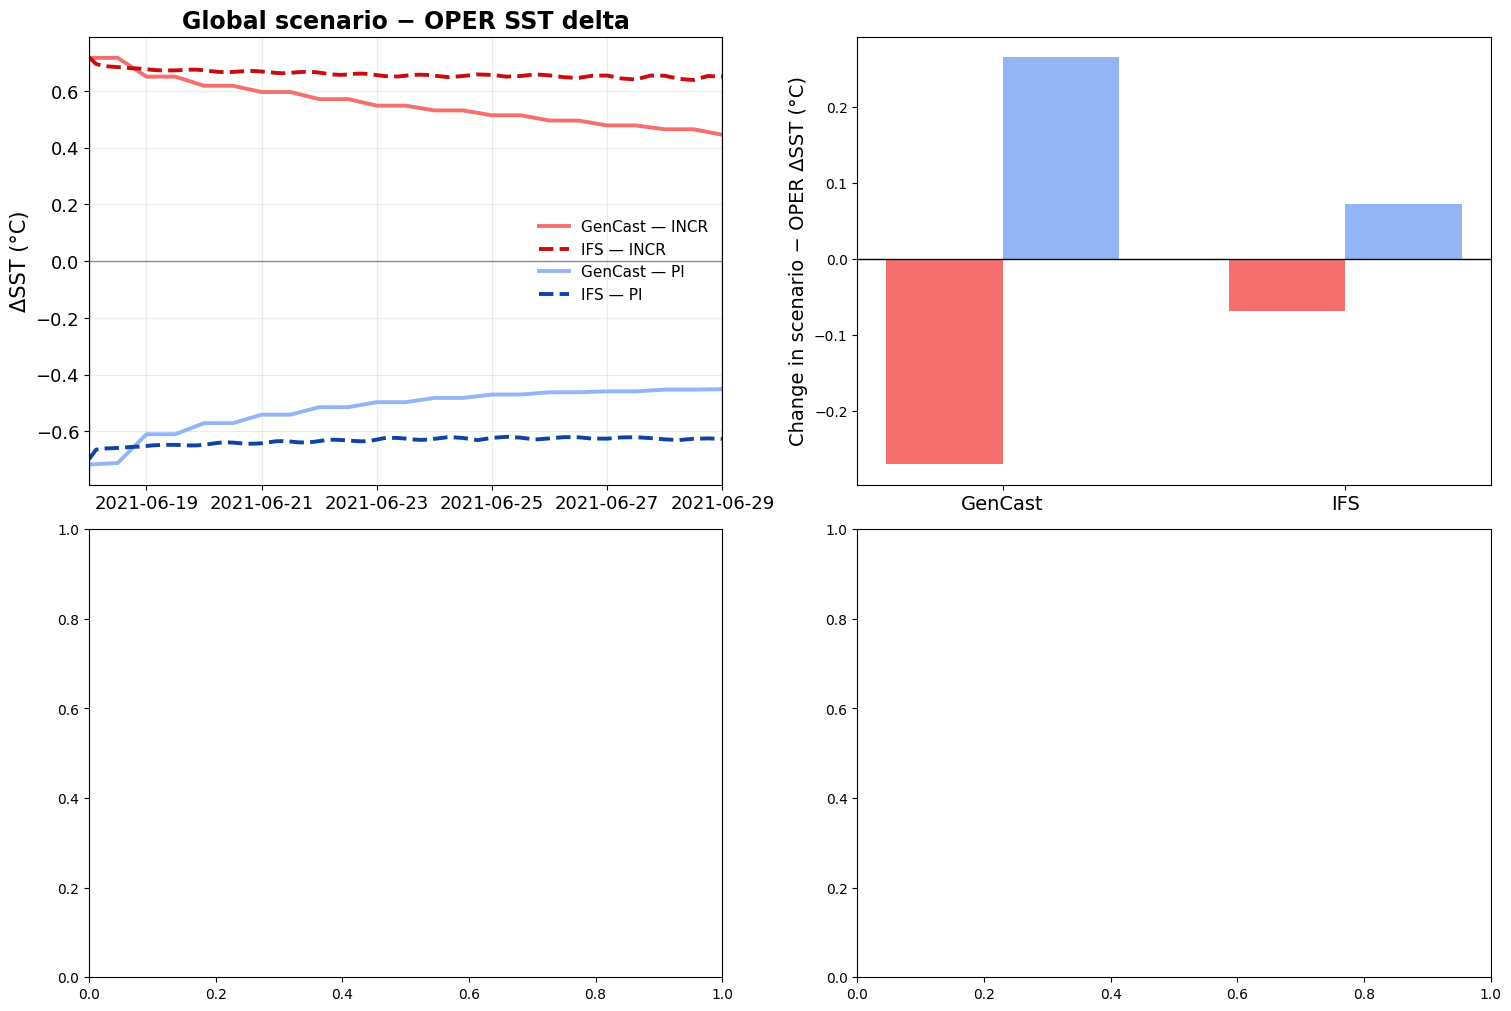

In [38]:
# ================================================================
# Arctic contribution to CHANGE in scenario-vs-OPER SST delta
#
# Comparison:
#   2021-06-18 00 UTC  ->  2021-06-29 00 UTC
#
# This directly tests:
#
#   "Does GenCast's INCR-OPER SST delta decrease more strongly
#    than IFS's, and how much of that decrease comes from
#    the Arctic?"
#
# And the analogous question for PI.
# ================================================================


# ================================================================
# Times of interest
# ================================================================
t0 = np.datetime64("2021-06-18T00:00:00")
t1 = np.datetime64("2021-06-29T00:00:00")


# ================================================================
# Load OPER fields
# ================================================================

gencast_oper = (
    open_var(
        Gencast_unperturbed[0],
        VAR_GENCAST,
    )
    - 273.15
)

ifs_oper = (
    open_var(
        IFS_unperturbed[0],
        VAR_IFS,
    )
    - 273.15
)


# ================================================================
# Ocean mask
#
# Use GenCast's ocean mask, consistent with your previous analysis.
# ================================================================

ocean_mask = (
    gencast_oper
    .isel(time=0)
    .notnull()
    .squeeze(drop=True)
)


# ================================================================
# Arctic mask: >= 66.5 N
# ================================================================

arctic_mask = gencast_oper.lat >= 66.5

arctic_ocean_mask = (
    ocean_mask
    & arctic_mask
)


# ================================================================
# Latitude area weights
# ================================================================

weights = np.cos(
    np.deg2rad(gencast_oper.lat)
)


# ================================================================
# Arctic fraction of total ocean area
# ================================================================

global_ocean_area = (
    weights
    .where(ocean_mask)
    .sum(dim=("lat", "lon"))
)

arctic_ocean_area = (
    weights
    .where(arctic_ocean_mask)
    .sum(dim=("lat", "lon"))
)

arctic_area_fraction = (
    arctic_ocean_area / global_ocean_area
).compute().item()

print(
    f"Arctic ocean area fraction: "
    f"{100 * arctic_area_fraction:.2f}%"
)


# ================================================================
# Helper functions
# ================================================================

def area_mean(da, mask):
    """Area-weighted mean over lat/lon using the supplied mask."""

    return (
        da.where(mask)
        .weighted(weights)
        .mean(
            dim=("lat", "lon"),
            skipna=True,
        )
        .squeeze(drop=True)
    )


def get_two_times(da):
    """Return fields at the two comparison times."""

    da_t0 = da.sel(
        time=t0,
        method="nearest",
    )

    da_t1 = da.sel(
        time=t1,
        method="nearest",
    )

    return da_t0, da_t1


# ================================================================
# Load scenarios
# ================================================================

gencast_scenarios = {}

for name, paths in Gencast_scenarios.items():

    gencast_scenarios[name] = (
        open_var(
            paths[0],
            VAR_GENCAST,
        )
        - 273.15
    )


ifs_scenarios = {}

for name, paths in IFS_scenarios.items():

    ifs_scenarios[name] = (
        open_var(
            paths[0],
            VAR_IFS,
        )
        - 273.15
    )


# ================================================================
# Calculate scenario-vs-OPER deltas
# ================================================================

gencast_delta = {}
ifs_delta = {}

for name in ("incr", "pi"):

    gencast_delta[name] = (
        gencast_scenarios[name]
        - gencast_oper
    )

    ifs_delta[name] = (
        ifs_scenarios[name]
        - ifs_oper
    )


# ================================================================
# Store results
# ================================================================

results = {}


# ================================================================
# Analyse each model/scenario
# ================================================================

for model_name, delta_dict in [
    ("GenCast", gencast_delta),
    ("IFS", ifs_delta),
]:

    results[model_name] = {}

    for scenario in ("incr", "pi"):

        delta = delta_dict[scenario]

        # --------------------------------------------------------
        # Select the two times
        # --------------------------------------------------------
        delta_t0 = delta.sel(
            time=t0,
            method="nearest",
        )

        delta_t1 = delta.sel(
            time=t1,
            method="nearest",
        )

        # --------------------------------------------------------
        # Global ocean means
        # --------------------------------------------------------
        global_t0 = area_mean(
            delta_t0,
            ocean_mask,
        )

        global_t1 = area_mean(
            delta_t1,
            ocean_mask,
        )

        # --------------------------------------------------------
        # Arctic ocean means
        # --------------------------------------------------------
        arctic_t0 = area_mean(
            delta_t0,
            arctic_ocean_mask,
        )

        arctic_t1 = area_mean(
            delta_t1,
            arctic_ocean_mask,
        )

        # --------------------------------------------------------
        # Change in scenario-vs-OPER delta
        #
        # Negative = delta has cooled/decreased
        # Positive = delta has warmed/increased
        # --------------------------------------------------------
        global_change = global_t1 - global_t0

        arctic_change = arctic_t1 - arctic_t0

        # --------------------------------------------------------
        # Arctic contribution to global change
        # --------------------------------------------------------
        arctic_contribution = (
            arctic_area_fraction
            * arctic_change
        )

        # --------------------------------------------------------
        # Fraction of global change originating from Arctic
        # --------------------------------------------------------
        arctic_fraction_of_change = (
            arctic_contribution
            / global_change
        )

        results[model_name][scenario] = {
            "delta_t0": global_t0,
            "delta_t1": global_t1,
            "global_change": global_change,
            "arctic_t0": arctic_t0,
            "arctic_t1": arctic_t1,
            "arctic_change": arctic_change,
            "arctic_contribution": arctic_contribution,
            "arctic_fraction_of_change": arctic_fraction_of_change,
        }


# ================================================================
# PRINT RESULTS
# ================================================================

print("\n")
print("=" * 100)
print("CHANGE IN SCENARIO - OPER SST DELTA")
print("2021-06-18 00 UTC -> 2021-06-29 00 UTC")
print("=" * 100)

for model in ("GenCast", "IFS"):

    print(f"\n{model}")
    print("-" * 100)

    for scenario in ("incr", "pi"):

        r = results[model][scenario]

        print(f"\n  {scenario.upper()}")

        print(
            "  Global ΔSST at 18 Jun:       "
            f"{float(r['delta_t0'].compute()): .4f} °C"
        )

        print(
            "  Global ΔSST at 29 Jun:       "
            f"{float(r['delta_t1'].compute()): .4f} °C"
        )

        print(
            "  CHANGE in global ΔSST:       "
            f"{float(r['global_change'].compute()): .4f} °C"
        )

        print(
            "  Arctic ΔSST at 18 Jun:       "
            f"{float(r['arctic_t0'].compute()): .4f} °C"
        )

        print(
            "  Arctic ΔSST at 29 Jun:       "
            f"{float(r['arctic_t1'].compute()): .4f} °C"
        )

        print(
            "  CHANGE in Arctic ΔSST:       "
            f"{float(r['arctic_change'].compute()): .4f} °C"
        )

        print(
            "  Arctic contribution:         "
            f"{float(r['arctic_contribution'].compute()): .4f} °C"
        )

        print(
            "  Arctic share of global:      "
            f"{100 * float(r['arctic_fraction_of_change'].compute()): .2f}%"
        )


# ================================================================
# Direct GenCast vs IFS comparison
#
# This is probably the most important diagnostic for your
# scientific question.
# ================================================================

print("\n")
print("=" * 100)
print("GenCast vs IFS: DIFFERENCE IN THE CHANGE OF THE DELTA")
print("2021-06-18 00 UTC -> 2021-06-29 00 UTC")
print("=" * 100)

for scenario in ("incr", "pi"):

    g = results["GenCast"][scenario]
    i = results["IFS"][scenario]

    # ------------------------------------------------------------
    # Difference between models in the evolution of the delta
    # ------------------------------------------------------------
    global_model_difference = (
        g["global_change"]
        - i["global_change"]
    )

    arctic_model_difference = (
        g["arctic_change"]
        - i["arctic_change"]
    )

    # Arctic contribution to that model difference
    arctic_contribution_to_model_difference = (
        arctic_area_fraction
        * arctic_model_difference
    )

    fraction_of_model_difference = (
        arctic_contribution_to_model_difference
        / global_model_difference
    )

    print(f"\n{scenario.upper()}")

    print(
        "  GenCast global delta change: "
        f"{float(g['global_change'].compute()): .4f} °C"
    )

    print(
        "  IFS global delta change:     "
        f"{float(i['global_change'].compute()): .4f} °C"
    )

    print(
        "  GenCast - IFS global:        "
        f"{float(global_model_difference.compute()): .4f} °C"
    )

    print(
        "  GenCast Arctic delta change: "
        f"{float(g['arctic_change'].compute()): .4f} °C"
    )

    print(
        "  IFS Arctic delta change:     "
        f"{float(i['arctic_change'].compute()): .4f} °C"
    )

    print(
        "  GenCast - IFS Arctic:        "
        f"{float(arctic_model_difference.compute()): .4f} °C"
    )

    print(
        "  Arctic contribution to\n"
        "  GenCast-IFS global difference:"
        f" {float(arctic_contribution_to_model_difference.compute()): .4f} °C"
    )

    print(
        "  Arctic fraction of the\n"
        "  GenCast-IFS difference:      "
        f"{100 * float(fraction_of_model_difference.compute()): .2f}%"
    )


# ================================================================
# Prepare plotting arrays
# ================================================================

scenario_colors = {
    "incr": incr_col_gencast,
    "pi": pi_col_gencast,
}

ifs_scenario_colors = {
    "incr": incr_col_orig,
    "pi": pi_col_orig,
}

# ================================================================
# Plot
# ================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
    constrained_layout=True,
)


# ================================================================
# PANEL 1 — TOP LEFT
# Scenario-vs-OPER global delta
# ================================================================

ax = axes[0, 0]

for scenario in ("incr", "pi"):

    # GenCast
    delta = gencast_delta[scenario]

    delta_global = (
        delta
        .where(ocean_mask)
        .weighted(weights)
        .mean(
            dim=("lat", "lon"),
            skipna=True,
        )
    )

    ax.plot(
        delta_global.time,
        delta_global,
        color=scenario_colors[scenario],
        linewidth=2.8,
        label=f"GenCast — {scenario.upper()}",
    )

    # IFS
    delta = ifs_delta[scenario]

    delta_global = (
        delta
        .where(ocean_mask)
        .weighted(weights)
        .mean(
            dim=("lat", "lon"),
            skipna=True,
        )
    )

    ax.plot(
        delta_global.time,
        delta_global,
        color=ifs_scenario_colors[scenario],
        linewidth=2.8,
        linestyle="--",
        label=f"IFS — {scenario.upper()}",
    )

ax.axvline(
    t0,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.axvline(
    t1,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    alpha=0.4,
)

ax.set_xlim(t0, t1)

ax.set_title(
    "Global scenario − OPER SST delta",
    fontsize=17,
    fontweight="bold",
)

ax.set_ylabel(
    "ΔSST (°C)",
    fontsize=15,
)

ax.grid(
    alpha=0.25,
)

ax.tick_params(
    labelsize=13,
)

ax.legend(
    frameon=False,
    fontsize=11,
)


# ================================================================
# PANEL 2 — TOP RIGHT
# Change in global delta between the two dates
#
# This is the direct "does GenCast cool faster than IFS?"
# diagnostic.
# ================================================================

models = ["GenCast", "IFS"]
x = np.arange(len(models))

width = 0.34

incr_changes = [
    float(
        results["GenCast"]["incr"]["global_change"]
        .compute()
    ),
    float(
        results["IFS"]["incr"]["global_change"]
        .compute()
    ),
]

pi_changes = [
    float(
        results["GenCast"]["pi"]["global_change"]
        .compute()
    ),
    float(
        results["IFS"]["pi"]["global_change"]
        .compute()
    ),
]

ax = axes[0, 1]

ax.bar(
    x - width / 2,
    incr_changes,
    width,
    label="INCR",
    color=incr_col_gencast,
)

ax.bar(
    x + width / 2,
    pi_changes,
    width,
    label="PI",
    color=pi_col_gencast,
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_xticks(x)

ax.set_xticklabels(
    models,
    fontsize=14,
)

ax.set_ylabel(
    "Change in scenario − OPER ΔSST (°C)",
    fontsize=14,
)

ax.set_title(
    "Global change in SST delta\n"
    f"18 Jun {pd.Timestamp(t0).strftime('%d %b %H:%M')} → 29 Jun {pd.Timestamp(t1).strftime('%d %b %H:%M')}",
    fontsize=17,
    fontweight="bold",
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False,
    fontsize=11,
)


# ================================================================
# PANEL 3 — BOTTOM LEFT
# Arctic scenario-vs-OPER delta
# ================================================================

ax = axes[1, 0]

for scenario in ("incr", "pi"):

    # GenCast
    delta = gencast_delta[scenario]

    delta_arctic = (
        delta
        .where(arctic_ocean_mask)
        .weighted(weights)
        .mean(
            dim=("lat", "lon"),
            skipna=True,
        )
    )

    ax.plot(
        delta_arctic.time,
        delta_arctic,
        color=scenario_colors[scenario],
        linewidth=2.8,
        label=f"GenCast — {scenario.upper()}",
    )

    # IFS
    delta = ifs_delta[scenario]

    delta_arctic = (
        delta
        .where(arctic_ocean_mask)
        .weighted(weights)
        .mean(
            dim=("lat", "lon"),
            skipna=True,
        )
    )

    ax.plot(
        delta_arctic.time,
        delta_arctic,
        color=ifs_scenario_colors[scenario],
        linewidth=2.8,
        linestyle="--",
        label=f"IFS — {scenario.upper()}",
    )

ax.axvline(
    t0,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.axvline(
    t1,
    color="black",
    linewidth=1,
    alpha=0.5,
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    alpha=0.4,
)

ax.set_xlim(t0, t1)

ax.set_title(
    "Arctic scenario − OPER SST delta",
    fontsize=17,
    fontweight="bold",
)

ax.set_ylabel(
    "Arctic ΔSST (°C)",
    fontsize=15,
)

ax.grid(
    alpha=0.25,
)

ax.tick_params(
    labelsize=13,
)

ax.legend(
    frameon=False,
    fontsize=11,
)


# ================================================================
# PANEL 4 — BOTTOM RIGHT
# Percentage of global temporal change from Arctic
# ================================================================

incr_arctic_fraction = [
    100 * float(
        results["GenCast"]["incr"]
        ["arctic_fraction_of_change"]
        .compute()
    ),
    100 * float(
        results["IFS"]["incr"]
        ["arctic_fraction_of_change"]
        .compute()
    ),
]

pi_arctic_fraction = [
    100 * float(
        results["GenCast"]["pi"]
        ["arctic_fraction_of_change"]
        .compute()
    ),
    100 * float(
        results["IFS"]["pi"]
        ["arctic_fraction_of_change"]
        .compute()
    ),
]

ax = axes[1, 1]

ax.bar(
    x - width / 2,
    incr_arctic_fraction,
    width,
    label="INCR",
    color=incr_col_gencast,
)

ax.bar(
    x + width / 2,
    pi_arctic_fraction,
    width,
    label="PI",
    color=pi_col_gencast,
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_xticks(x)

ax.set_xticklabels(
    models,
    fontsize=14,
)

ax.set_ylabel(
    "Arctic share of global change (%)",
    fontsize=14,
)

ax.set_title(
    "Arctic contribution to temporal change\n"
    f"{pd.Timestamp(t0).strftime('%d %b %H:%M')} → {pd.Timestamp(t1).strftime('%d %b %H:%M')}",
    fontsize=17,
    fontweight="bold",
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False,
    fontsize=11,
)


# ================================================================
# Overall formatting
# ================================================================

fig.suptitle(
    "Arctic Contribution to Evolution of Scenario − OPER SST Delta",
    fontsize=20,
    fontweight="bold",
    y=1.02,
)

plt.show()

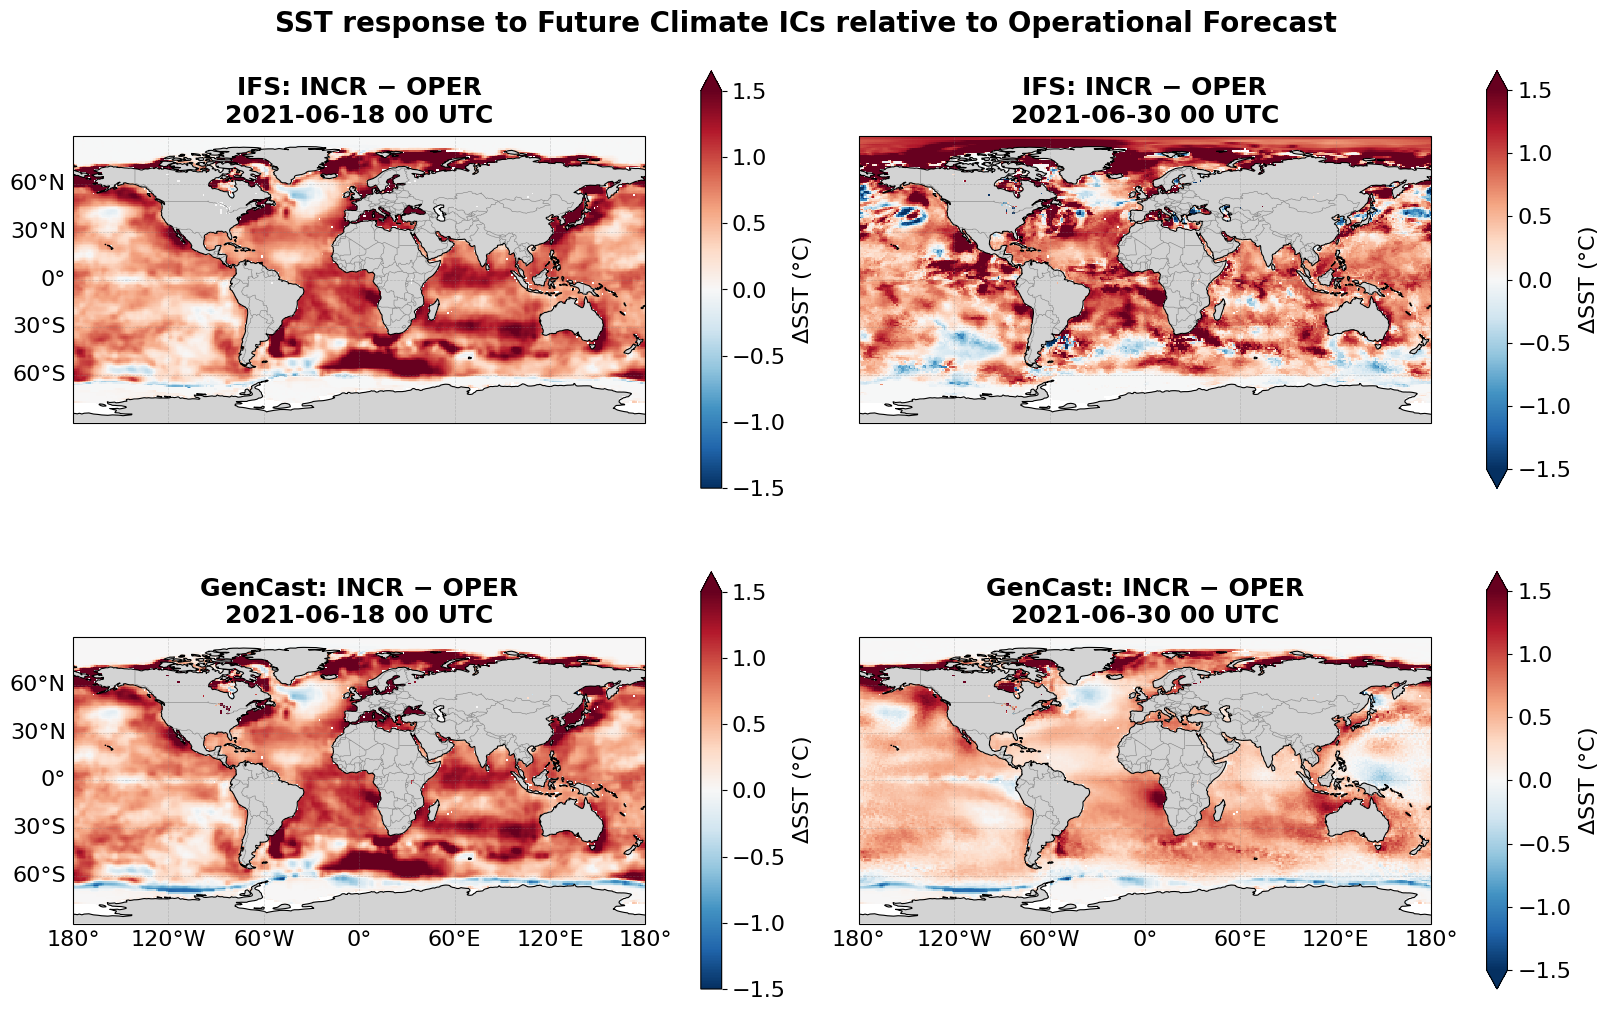

In [15]:
# ================================================================
# Load spatial SST fields: OPER and INCR
# ================================================================

# ------------------------------------------------
# GenCast
# ------------------------------------------------
gencast_oper = (
    open_var(
        Gencast_unperturbed[0],
        VAR_GENCAST,
    )
    - 273.15
)

gencast_incr = (
    open_var(
        Gencast_scenarios["incr"][0],
        VAR_GENCAST,
    )
    - 273.15
)

# ------------------------------------------------
# IFS
# Apply the GenCast ocean mask
# ------------------------------------------------
ifs_oper = (
    open_var(
        IFS_unperturbed[0],
        VAR_IFS,
    )
    - 273.15
).where(ocean_mask)

ifs_incr = (
    open_var(
        IFS_scenarios["incr"][0],
        VAR_IFS,
    )
    - 273.15
).where(ocean_mask)


# ================================================================
# Calculate delta SST relative to OPER
# ================================================================

gencast_delta = gencast_incr - gencast_oper
ifs_delta = ifs_incr - ifs_oper


# ================================================================
# Select times
# ================================================================

# t = 0
ifs_delta_t0 = ifs_delta.isel(time=0)
gencast_delta_t0 = gencast_delta.isel(time=1)

# 2021-06-30
# isel(time=...) is used after finding the matching valid-time index
ifs_time_30 = np.where(
    ifs_delta.time.dt.strftime("%Y-%m-%d").values == "2021-06-30"
)[0][0]

gencast_time_30 = np.where(
    gencast_delta.time.dt.strftime("%Y-%m-%d").values == "2021-06-30"
)[0][0]

ifs_delta_30 = ifs_delta.isel(time=ifs_time_30)
gencast_delta_30 = gencast_delta.isel(time=gencast_time_30)


# ================================================================
# Common symmetric colour scale
# ================================================================

max_abs = max(
    abs(float(ifs_delta_t0.min(skipna=True))),
    abs(float(ifs_delta_t0.max(skipna=True))),
    abs(float(ifs_delta_30.min(skipna=True))),
    abs(float(ifs_delta_30.max(skipna=True))),
    abs(float(gencast_delta_t0.min(skipna=True))),
    abs(float(gencast_delta_t0.max(skipna=True))),
    abs(float(gencast_delta_30.min(skipna=True))),
    abs(float(gencast_delta_30.max(skipna=True))),
)

#vmin = -max_abs
#vmax = max_abs
# ================================================================
# Fixed colour scale
# ================================================================

vmin = -1.5
vmax = 1.5


# ================================================================
# Four-panel delta plot
# ================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

# Flatten for easier looping
axes = axes.ravel()


# ================================================================
# Plot information
# ================================================================

fields = [
    ifs_delta_t0,
    ifs_delta_30,
    gencast_delta_t0,
    gencast_delta_30,
]

titles = [
    f"IFS: INCR − OPER\n"
    f"{ifs_delta.time.isel(time=0).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS: INCR − OPER\n"
    f"{ifs_delta.time.isel(time=ifs_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"GenCast: INCR − OPER\n"
    f"{gencast_delta.time.isel(time=1).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"GenCast: INCR − OPER\n"
    f"{gencast_delta.time.isel(time=gencast_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",
]


# ================================================================
# Plot each panel
# ================================================================

for ax, field, title in zip(axes, fields, titles):

    # ------------------------------------------------------------
    # SST delta
    # ------------------------------------------------------------
    im = field.plot(
        ax=ax,
        x="lon",
        y="lat",
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        center=0,
        add_colorbar=True,
        cbar_kwargs={
            "label": r"$\Delta$SST (°C)",
            "shrink": 0.85,
        },
    )

    # Colourbar formatting
    im.colorbar.ax.tick_params(labelsize=16)
    im.colorbar.set_label(
        r"$\Delta$SST (°C)",
        fontsize=16,
    )

    # ------------------------------------------------------------
    # Geographic features
    # ------------------------------------------------------------
    ax.coastlines(
        resolution="110m",
        linewidth=0.8,
        color="black",
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.4,
        edgecolor="gray",
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="lightgray",
        edgecolor="none",
        zorder=0,
    )

    # ------------------------------------------------------------
    # Gridlines
    # ------------------------------------------------------------
    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.35,
        linestyle="--",
    )

    gl.top_labels = False
    gl.right_labels = False

    # Lat/lon number size
    gl.xlabel_style = {"size": 16}
    gl.ylabel_style = {"size": 16}

    # Longitude labels only on bottom row
    if ax in axes[:2]:
        gl.bottom_labels = False

    # Latitude labels only on left column
    if ax in [axes[1], axes[3]]:
        gl.left_labels = False

    # ------------------------------------------------------------
    # Panel title
    # ------------------------------------------------------------
    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        pad=10,
    )


# ================================================================
# Overall title
# ================================================================

fig.suptitle(
    "SST response to Future Climate ICs relative to Operational Forecast",
    fontsize=20,
    fontweight="bold",
    y=1.02,
)

plt.show()

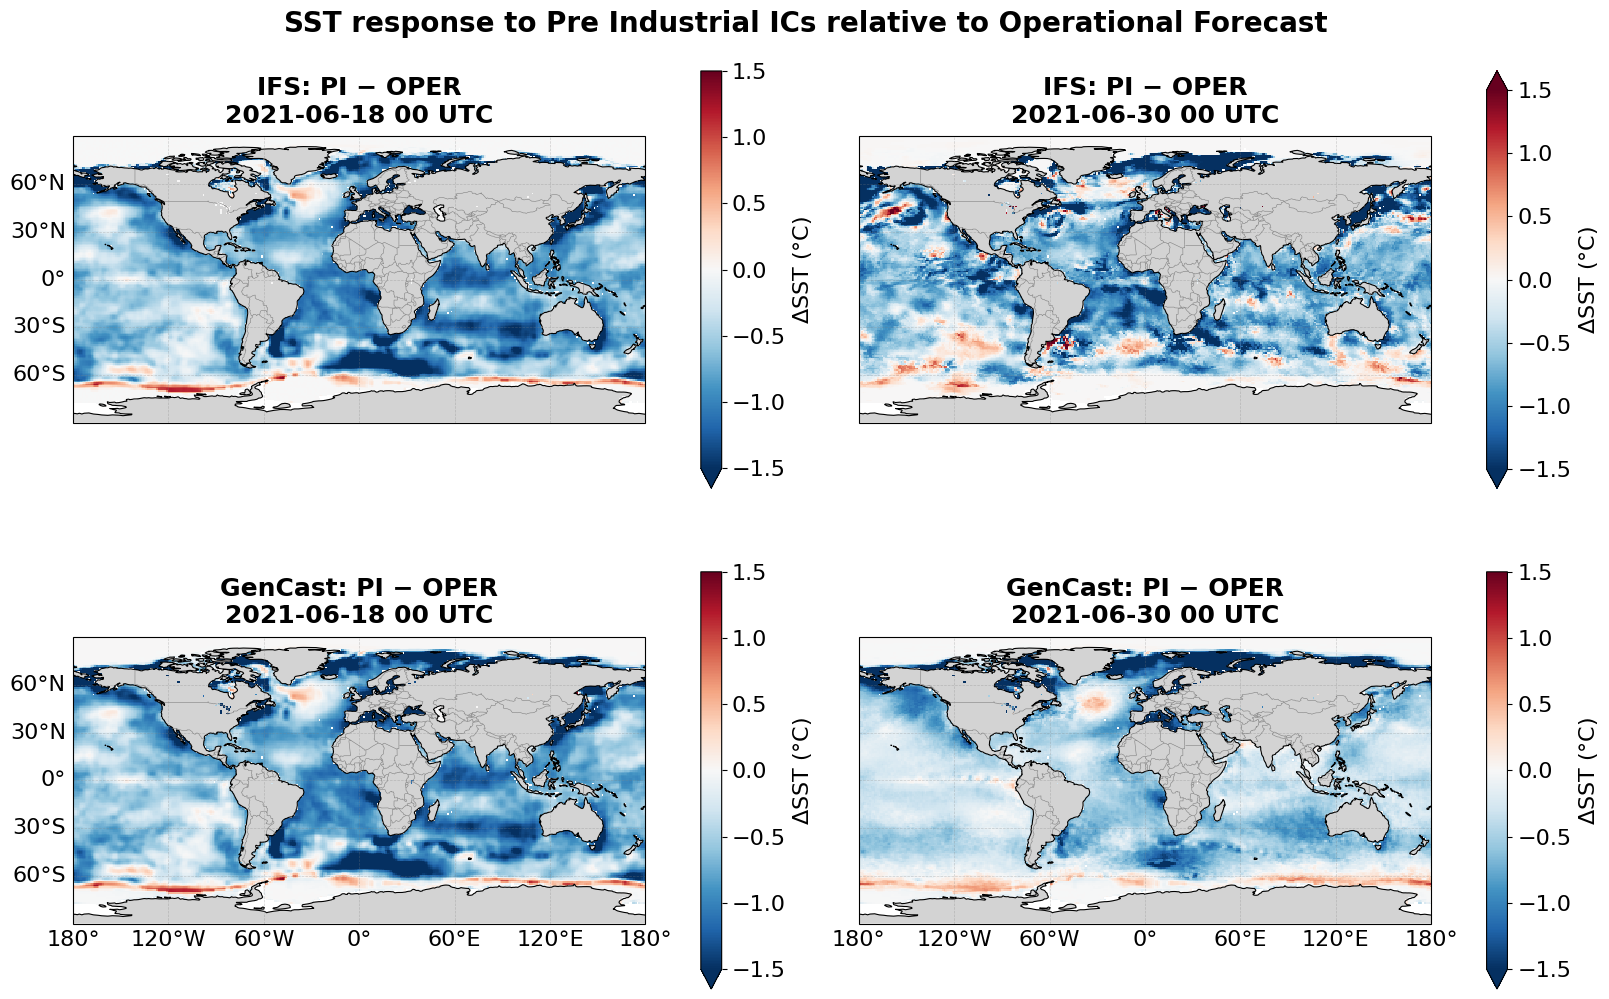

In [16]:
# ================================================================
# Load spatial SST fields: OPER and PI
# ================================================================

# ------------------------------------------------
# GenCast
# ------------------------------------------------
gencast_oper = (
    open_var(
        Gencast_unperturbed[0],
        VAR_GENCAST,
    )
    - 273.15
)

gencast_pi = (
    open_var(
        Gencast_scenarios["pi"][0],
        VAR_GENCAST,
    )
    - 273.15
)

# ------------------------------------------------
# IFS
# Apply the GenCast ocean mask
# ------------------------------------------------
ifs_oper = (
    open_var(
        IFS_unperturbed[0],
        VAR_IFS,
    )
    - 273.15
).where(ocean_mask)

ifs_pi = (
    open_var(
        IFS_scenarios["pi"][0],
        VAR_IFS,
    )
    - 273.15
).where(ocean_mask)


# ================================================================
# Calculate delta SST relative to OPER
# ================================================================

gencast_delta = gencast_pi - gencast_oper
ifs_delta = ifs_pi - ifs_oper


# ================================================================
# Select times
# ================================================================

# t = 0
ifs_delta_t0 = ifs_delta.isel(time=0)
gencast_delta_t0 = gencast_delta.isel(time=1)

# 2021-06-30
# isel(time=...) is used after finding the matching valid-time index
ifs_time_30 = np.where(
    ifs_delta.time.dt.strftime("%Y-%m-%d").values == "2021-06-30"
)[0][0]

gencast_time_30 = np.where(
    gencast_delta.time.dt.strftime("%Y-%m-%d").values == "2021-06-30"
)[0][0]

ifs_delta_30 = ifs_delta.isel(time=ifs_time_30)
gencast_delta_30 = gencast_delta.isel(time=gencast_time_30)


# ================================================================
# Common symmetric colour scale
# ================================================================

max_abs = max(
    abs(float(ifs_delta_t0.min(skipna=True))),
    abs(float(ifs_delta_t0.max(skipna=True))),
    abs(float(ifs_delta_30.min(skipna=True))),
    abs(float(ifs_delta_30.max(skipna=True))),
    abs(float(gencast_delta_t0.min(skipna=True))),
    abs(float(gencast_delta_t0.max(skipna=True))),
    abs(float(gencast_delta_30.min(skipna=True))),
    abs(float(gencast_delta_30.max(skipna=True))),
)

#vmin = -max_abs
#vmax = max_abs


# ================================================================
# Fixed colour scale
# ================================================================

vmin = -1.5
vmax = 1.5


# ================================================================
# Four-panel delta plot
# ================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

# Flatten for easier looping
axes = axes.ravel()


# ================================================================
# Plot information
# ================================================================

fields = [
    ifs_delta_t0,
    ifs_delta_30,
    gencast_delta_t0,
    gencast_delta_30,
]

titles = [
    f"IFS: PI − OPER\n"
    f"{ifs_delta.time.isel(time=0).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS: PI − OPER\n"
    f"{ifs_delta.time.isel(time=ifs_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"GenCast: PI − OPER\n"
    f"{gencast_delta.time.isel(time=1).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"GenCast: PI − OPER\n"
    f"{gencast_delta.time.isel(time=gencast_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",
]


# ================================================================
# Plot each panel
# ================================================================

for ax, field, title in zip(axes, fields, titles):

    # ------------------------------------------------------------
    # SST delta
    # ------------------------------------------------------------
    im = field.plot(
        ax=ax,
        x="lon",
        y="lat",
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        center=0,
        add_colorbar=True,
        cbar_kwargs={
            "label": r"$\Delta$SST (°C)",
            "shrink": 0.85,
        },
    )

    # Colourbar formatting
    im.colorbar.ax.tick_params(labelsize=16)
    im.colorbar.set_label(
        r"$\Delta$SST (°C)",
        fontsize=16,
    )

    # ------------------------------------------------------------
    # Geographic features
    # ------------------------------------------------------------
    ax.coastlines(
        resolution="110m",
        linewidth=0.8,
        color="black",
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.4,
        edgecolor="gray",
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="lightgray",
        edgecolor="none",
        zorder=0,
    )

    # ------------------------------------------------------------
    # Gridlines
    # ------------------------------------------------------------
    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.35,
        linestyle="--",
    )

    gl.top_labels = False
    gl.right_labels = False

    # Lat/lon number size
    gl.xlabel_style = {"size": 16}
    gl.ylabel_style = {"size": 16}

    # Longitude labels only on bottom row
    if ax in axes[:2]:
        gl.bottom_labels = False

    # Latitude labels only on left column
    if ax in [axes[1], axes[3]]:
        gl.left_labels = False

    # ------------------------------------------------------------
    # Panel title
    # ------------------------------------------------------------
    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        pad=10,
    )


# ================================================================
# Overall title
# ================================================================

fig.suptitle(
    "SST response to Pre Industrial ICs relative to Operational Forecast",
    fontsize=20,
    fontweight="bold",
    y=1.02,
)

plt.show()

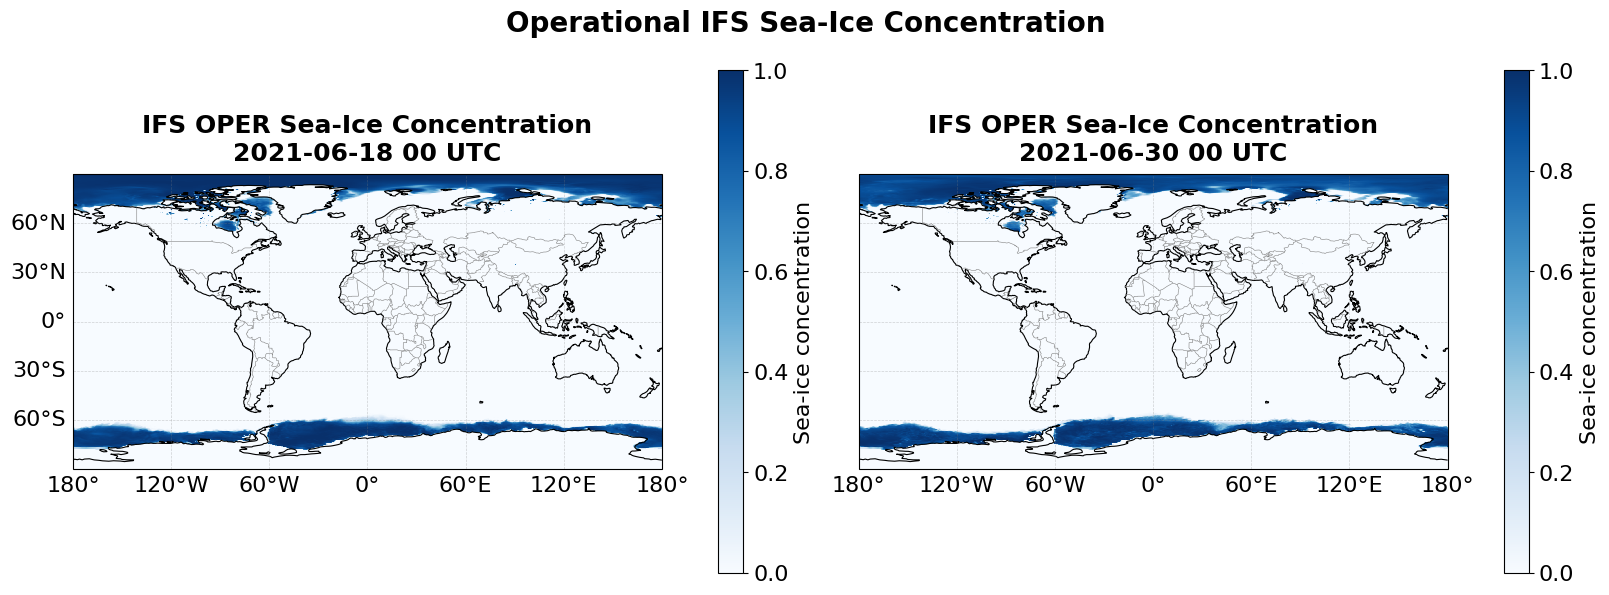

In [ ]:
# ================================================================
# Load sea-ice concentration: IFS OPER and INCR
# ================================================================

VAR_SIC = "siconc"

# ------------------------------------------------
# IFS OPER
# ------------------------------------------------
ifs_sic_oper = open_var(
    IFS_unperturbed[0],
    VAR_SIC,
)

# ------------------------------------------------
# IFS INCR
# ------------------------------------------------
ifs_sic_incr = open_var(
    IFS_scenarios["incr"][0],
    VAR_SIC,
)


# ================================================================
# Select times
# ================================================================

# ------------------------------------------------
# t = 0
# ------------------------------------------------
ifs_sic_oper_t0 = ifs_sic_oper.isel(time=0)
ifs_sic_incr_t0 = ifs_sic_incr.isel(time=0)


# ------------------------------------------------
# 2021-06-30
# ------------------------------------------------
ifs_sic_oper_time_30 = np.where(
    ifs_sic_oper.time.dt.strftime("%Y-%m-%d").values == "2021-06-30"
)[0][0]

ifs_sic_incr_time_30 = np.where(
    ifs_sic_incr.time.dt.strftime("%Y-%m-%d").values == "2021-06-30"
)[0][0]

ifs_sic_oper_30 = ifs_sic_oper.isel(time=ifs_sic_oper_time_30)
ifs_sic_incr_30 = ifs_sic_incr.isel(time=ifs_sic_incr_time_30)


# ================================================================
# Plot: OPER and INCR
# ================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    subplot_kw={
        "projection": ccrs.NorthPolarStereo(),
    },
    constrained_layout=True,
)

# Flatten for easier looping
axes = axes.ravel()


# ================================================================
# Plot information
# ================================================================

fields = [
    ifs_sic_oper_t0,
    ifs_sic_oper_30,
    ifs_sic_incr_t0,
    ifs_sic_incr_30,
]

titles = [
    f"IFS OPER\n"
    f"{ifs_sic_oper.time.isel(time=0).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS OPER\n"
    f"{ifs_sic_oper.time.isel(time=ifs_sic_oper_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS INCR\n"
    f"{ifs_sic_incr.time.isel(time=0).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS INCR\n"
    f"{ifs_sic_incr.time.isel(time=ifs_sic_incr_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",
]


# ================================================================
# Plot each panel
# ================================================================

for ax, field, title in zip(axes, fields, titles):

    # ------------------------------------------------------------
    # Sea-ice concentration
    # ------------------------------------------------------------
    im = field.plot(
        ax=ax,
        x="lon",
        y="lat",
        transform=ccrs.PlateCarree(),
        cmap="Blues",
        vmin=0,
        vmax=1,
        add_colorbar=True,
        cbar_kwargs={
            "label": "Sea-ice concentration",
            "shrink": 0.85,
        },
    )

    # Colourbar formatting
    im.colorbar.ax.tick_params(labelsize=14)
    im.colorbar.set_label(
        "Sea-ice concentration",
        fontsize=14,
    )

    # ------------------------------------------------------------
    # Arctic extent
    # ------------------------------------------------------------
    ax.set_extent(
        [-180, 180, 45, 90],
        crs=ccrs.PlateCarree(),
    )

    # ------------------------------------------------------------
    # Geographic features
    # ------------------------------------------------------------
    ax.coastlines(
        resolution="110m",
        linewidth=0.8,
        color="black",
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.4,
        edgecolor="gray",
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="lightgray",
        edgecolor="none",
        zorder=0,
    )

    # ------------------------------------------------------------
    # Gridlines
    # ------------------------------------------------------------
    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.35,
        linestyle="--",
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {"size": 14}
    gl.ylabel_style = {"size": 14}

    # Polar projection: keep labels minimal
    gl.left_labels = False
    gl.bottom_labels = False

    # ------------------------------------------------------------
    # Panel title
    # ------------------------------------------------------------
    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        pad=10,
    )


# ================================================================
# Overall title
# ================================================================

fig.suptitle(
    "IFS Sea-Ice Concentration: Operational vs Increased CO₂",
    fontsize=20,
    fontweight="bold",
    y=1.02,
)

plt.show()

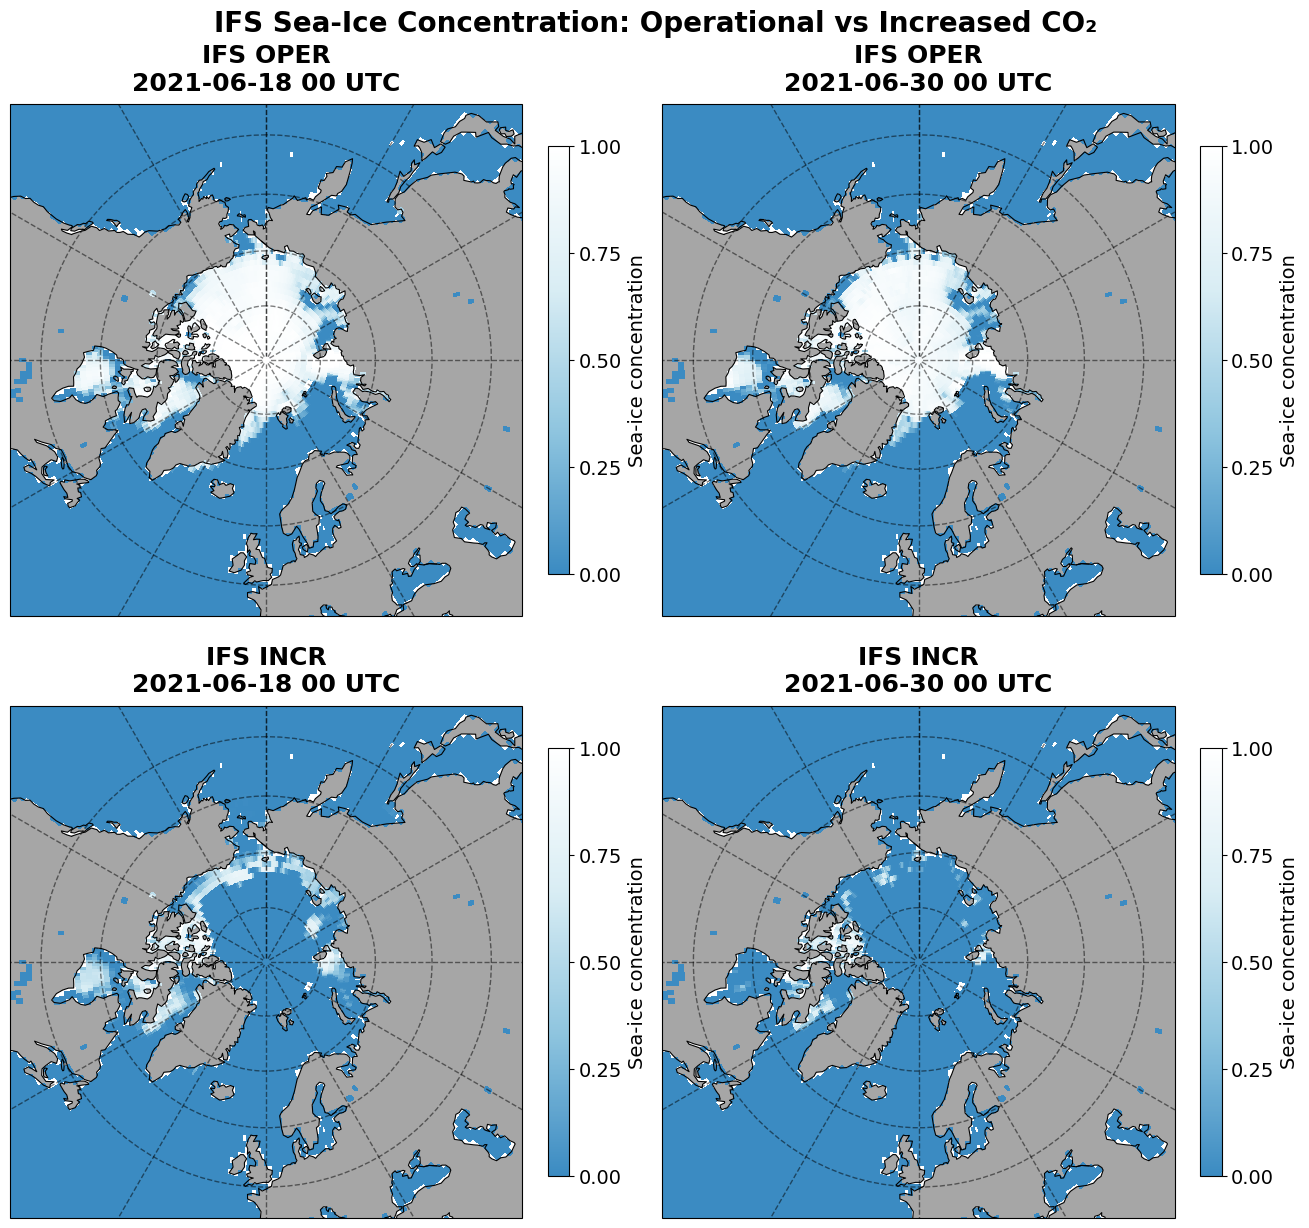

In [34]:
# ================================================================
# Load sea-ice concentration: IFS OPER and INCR
# ================================================================

VAR_SIC = "siconc"

# ------------------------------------------------
# IFS OPER
# ------------------------------------------------
ifs_sic_oper = open_var(
    IFS_unperturbed[0],
    VAR_SIC,
)

# ------------------------------------------------
# IFS INCR
# ------------------------------------------------
ifs_sic_incr = open_var(
    IFS_scenarios["incr"][0],
    VAR_SIC,
)


# ================================================================
# Select times
# ================================================================

# t = 0
ifs_sic_oper_t0 = ifs_sic_oper.isel(time=0)
ifs_sic_incr_t0 = ifs_sic_incr.isel(time=0)

# ------------------------------------------------
# 2021-06-30
# ------------------------------------------------
ifs_sic_oper_time_29 = np.where(
    ifs_sic_oper.time.dt.strftime("%Y-%m-%d").values == "2021-06-29"
)[0][0]

ifs_sic_incr_time_29 = np.where(
    ifs_sic_incr.time.dt.strftime("%Y-%m-%d").values == "2021-06-29"
)[0][0]

ifs_sic_oper_29 = ifs_sic_oper.isel(time=ifs_sic_oper_time_29)
ifs_sic_incr_29 = ifs_sic_incr.isel(time=ifs_sic_incr_time_29)


# ================================================================
# Plot information
# ================================================================

fields = [
    ifs_sic_oper_t0,
    ifs_sic_oper_30,
    ifs_sic_incr_t0,
    ifs_sic_incr_30,
]

titles = [
    f"IFS OPER\n"
    f"{ifs_sic_oper.time.isel(time=0).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS OPER\n"
    f"{ifs_sic_oper.time.isel(time=ifs_sic_oper_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS INCR\n"
    f"{ifs_sic_incr.time.isel(time=0).dt.strftime('%Y-%m-%d %H UTC').item()}",

    f"IFS INCR\n"
    f"{ifs_sic_incr.time.isel(time=ifs_sic_incr_time_30).dt.strftime('%Y-%m-%d %H UTC').item()}",
]


# ================================================================
# Colormap
#
# 0 concentration   -> blue ocean
# 1 concentration   -> white sea ice
# ================================================================

from matplotlib.colors import LinearSegmentedColormap

ice_cmap = LinearSegmentedColormap.from_list(
    "ocean_to_ice",
    [
        "#3b8bc2",   # open ocean
        "#8fc5df",   # low concentration
        "#d9edf4",   # high concentration
        "#ffffff",   # complete ice cover
    ],
)


# ================================================================
# Plot
# ================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 12),
    subplot_kw={
        "projection": ccrs.NorthPolarStereo(),
    },
    constrained_layout=True,
)

axes = axes.ravel()


# ================================================================
# Plot each panel
# ================================================================

for ax, field, title in zip(axes, fields, titles):

    # ------------------------------------------------------------
    # Arctic extent
    # ------------------------------------------------------------
    ax.set_extent(
        [-180, 180, 45, 90],
        crs=ccrs.PlateCarree(),
    )

    # ------------------------------------------------------------
    # LAND = grey
    #
    # Put this down first so that land is always grey.
    # ------------------------------------------------------------
    ax.add_feature(
        cfeature.LAND,
        facecolor="0.65",
        edgecolor="none",
        zorder=1,
    )

    # ------------------------------------------------------------
    # SEA ICE / OCEAN
    #
    # Mask land using the same ocean mask as the SST plots.
    #
    # siconc = 0 -> blue
    # siconc = 1 -> white
    # ------------------------------------------------------------
    field_ocean = field.where(ocean_mask)

    im = field_ocean.plot(
        ax=ax,
        x="lon",
        y="lat",
        transform=ccrs.PlateCarree(),
        cmap=ice_cmap,
        vmin=0,
        vmax=1,
        add_colorbar=True,
        zorder=2,
        cbar_kwargs={
            "label": "Sea-ice concentration (%)",
            "shrink": 0.80,
            "pad": 0.05,
        },
    )

    # ------------------------------------------------------------
    # Colourbar formatting
    # ------------------------------------------------------------
    im.colorbar.ax.tick_params(labelsize=14)

    im.colorbar.set_label(
        "Sea-ice concentration",
        fontsize=14,
    )

    im.colorbar.set_ticks(
        [0, 0.25, 0.5, 0.75, 1.0]
    )

    # ------------------------------------------------------------
    # Coastlines
    # ------------------------------------------------------------
    ax.coastlines(
        resolution="110m",
        linewidth=0.8,
        color="black",
        zorder=3,
    )

    # ------------------------------------------------------------
    # Gridlines
    # ------------------------------------------------------------
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=1.0,
        color="black",
        alpha=0.5,
        linestyle="--",
        xlocs=np.arange(-180, 181, 30),
        ylocs=np.arange(50, 91, 10),
        zorder=4,
    )

    # ------------------------------------------------------------
    # Panel title
    # ------------------------------------------------------------
    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        pad=10,
    )


# ================================================================
# Overall title
# ================================================================

fig.suptitle(
    "IFS Sea-Ice Concentration: Operational vs Increased CO₂",
    fontsize=20,
    fontweight="bold",
    y=1.02,
)

plt.show()

In [17]:
ds = xr.open_zarr(Gencast_unperturbed[0])

print(ds)
print("\nVariables:")
print(list(ds.data_vars))

<xarray.Dataset> Size: 35GB
Dimensions:                   (batch: 1, time: 32, lat: 181, lon: 360,
                               sample: 50, level: 13)
Coordinates:
  * batch                     (batch) int64 8B 0
  * time                      (time) timedelta64[ns] 256B -1 days +12:00:00 ....
  * lat                       (lat) float32 724B -90.0 -89.0 -88.0 ... 89.0 90.0
  * lon                       (lon) float32 1kB 0.0 1.0 2.0 ... 358.0 359.0
  * sample                    (sample) int64 400B 0 1 2 3 4 5 ... 45 46 47 48 49
  * level                     (level) int32 52B 50 100 150 200 ... 850 925 1000
Data variables: (12/18)
    10m_u_component_of_wind   (batch, time, lat, lon, sample) float32 417MB dask.array<chunksize=(1, 8, 46, 90, 13), meta=np.ndarray>
    10m_v_component_of_wind   (batch, time, lat, lon, sample) float32 417MB dask.array<chunksize=(1, 8, 46, 90, 13), meta=np.ndarray>
    2m_temperature            (batch, time, lat, lon, sample) float32 417MB dask.array<chunksi